# Semáforo de salud financiera empresarial

**Proyecto integrador** — Inteligencia de Negocios · Análisis de Datos · Aprendizaje Computacional
Instituto Tecnológico Metropolitano (ITM) · Equipo: Julián, Santiago, Jacobo y Oscar

## 0. Problema de negocio

Cuando una empresa entra en dificultades financieras, el problema suele verse en sus estados
financieros antes de que se vuelva una crisis: la liquidez cae, el endeudamiento sube o el
patrimonio se vuelve negativo. Detectar esas señales a tiempo le sirve a varios actores:

- **Entes de supervisión** (como la Superintendencia de Sociedades), para priorizar a qué
  empresas hacerles seguimiento.
- **Bancos y proveedores**, para decidir a quién otorgar crédito o plazos de pago.
- **Las mismas empresas**, para compararse con su sector y corregir el rumbo.

**Pregunta de negocio:** con el balance de una empresa en el año *t*, ¿podemos anticipar si
estará en **deterioro financiero** en el año *t+1*?

**Fuentes de datos** (públicas, Portal de Datos Abiertos de Colombia):

1. *Estados Financieros NIIF – Estado de Situación Financiera* (Supersociedades): balances de las
   empresas, una fila por empresa, cuenta y fecha de corte.
2. *10.000 Empresas más Grandes del País* (Supersociedades): sector, región, ciudad, ingresos y
   ganancia de cada empresa.

**Estructura del notebook:**

| Sección | Etapa |
|---|---|
| 1 | ETL: extracción, limpieza, integración y modelo estrella |
| 2 | Análisis exploratorio e inferencia estadística |
| 3 | Preparación de datos y modelos de aprendizaje supervisado |
| 4 | Conclusiones, recomendaciones y consideraciones éticas |

El dashboard de Power BI está en la carpeta `dashboard/`.

## 1. ETL — Extracción, transformación y carga

### 1.1 Extracción de datos por API

Las dos bases se publican en el Portal de Datos Abiertos, que usa la plataforma **Socrata**.
Socrata permite consultarlas con un lenguaje parecido a SQL (SoQL) directamente en la URL:

- `$select`: columnas a traer.
- `$where`: filtros.
- `$limit` y `$offset`: paginación.

Descargar por API, en lugar de bajar un archivo a mano, deja el proceso **automatizado y
reproducible**: cualquiera del equipo puede volver a ejecutar esta sección y obtener los mismos
datos.

La base de balances tiene cerca de **19,6 millones de filas**, así que no se descarga completa.
Se filtra en el servidor para traer solo lo que el proyecto necesita.

#### Configuración

Las rutas se construyen de forma **relativa** a la raíz del repositorio. Así el notebook
funciona en el computador de cualquier integrante.

In [1]:
import os
import io
import time
from pathlib import Path

import pandas as pd
import requests

# Raíz del repositorio: si el notebook se abre desde /notebooks, se sube un nivel
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = RAIZ / "data" / "raw"
DATA_PROCESSED = RAIZ / "data" / "processed"
DATA_RAW.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# Identificadores de las bases en datos.gov.co
URL_BASE = "https://www.datos.gov.co/resource/{}.csv"
ID_BALANCES = "pfdp-zks5"   # Estados Financieros NIIF - Estado de Situación Financiera
ID_EMPRESAS = "6cat-2gcs"   # 10.000 Empresas más Grandes del País

# Años de corte a descargar (balances de cierre de año)
ANIOS = list(range(2019, 2026))

# Token opcional de datos.gov.co (variable de entorno, nunca escrito en el código)
APP_TOKEN = os.getenv("DATOS_GOV_TOKEN")

print("Raíz del proyecto:", RAIZ.name)
print("Token configurado:", "sí" if APP_TOKEN else "no (la descarga funciona, pero puede ser más lenta)")

Raíz del proyecto: Final-AnalisisDatos
Token configurado: no (la descarga funciona, pero puede ser más lenta)


#### Función de descarga paginada

La API devuelve como máximo un número fijo de filas por consulta. La función pide los datos por
páginas de 50.000 filas hasta que una página llega vacía.

- El parámetro `$order=:id` ordena por el identificador interno de cada fila. Así ninguna fila
  se repite ni se pierde entre páginas.
- Si una página falla por un error de red, se reintenta hasta 3 veces antes de detenerse.
- Todo se lee como texto (`dtype=str`). La conversión de tipos se hace en la etapa de limpieza.

In [2]:
def descargar_socrata(id_base, params, tam_pagina=50_000, reintentos=3):
    """Descarga una consulta SoQL completa, página por página, y la devuelve como DataFrame."""
    url = URL_BASE.format(id_base)
    encabezados = {"X-App-Token": APP_TOKEN} if APP_TOKEN else {}
    paginas, offset = [], 0

    while True:
        # Orden por defecto: identificador interno de la fila (se puede cambiar con params)
        consulta = {"$order": ":id", **params, "$limit": tam_pagina, "$offset": offset}
        for intento in range(1, reintentos + 1):
            try:
                resp = requests.get(url, params=consulta, headers=encabezados, timeout=300)
                resp.raise_for_status()
                break
            except requests.RequestException as error:
                if intento == reintentos:
                    raise
                print(f"  Fallo de conexión en la página (offset={offset}), "
                      f"reintento {intento} de {reintentos - 1}...")
                time.sleep(5 * intento)

        if not resp.text.strip():
            break
        pagina = pd.read_csv(io.StringIO(resp.text), dtype=str)
        if pagina.empty:
            break
        paginas.append(pagina)
        offset += tam_pagina
        print(f"  {offset - tam_pagina + len(pagina):,} filas descargadas")
        if len(pagina) < tam_pagina:
            break

    return pd.concat(paginas, ignore_index=True) if paginas else pd.DataFrame()

#### Base 2: 10.000 Empresas más Grandes del País

Esta base se descarga primero y completa, porque es pequeña (50.000 filas: 10.000 empresas por
cada año de corte entre 2021 y 2025). Define el **universo de análisis**: solo se trabajará con
las empresas que aparecen en ella, que son las que tienen información de sector y ubicación.

Una revisión previa de la API mostró que el NIT viene como texto con decimales (por ejemplo
`"899999068.00"`). Aquí solo se le quita ese `.00` para poder filtrar la otra base. La
normalización completa del NIT se hace en la etapa de integración.

In [3]:
empresas_raw = descargar_socrata(ID_EMPRESAS, params={})
empresas_raw.to_csv(DATA_RAW / "empresas_10000_raw.csv", index=False)

print("Dimensiones:", empresas_raw.shape)
print("Columnas:", list(empresas_raw.columns))
empresas_raw.head()

  50,000 filas descargadas
Dimensiones: (50000, 14)
Columnas: ['nit', 'raz_n_social', 'supervisor', 'regi_n', 'departamento_domicilio', 'ciudad_domicilio', 'ciiu', 'macrosector', 'ingresos_operacionales', 'ganancia_p_rdida', 'total_activos', 'total_pasivos', 'total_patrimonio', 'a_o_de_corte']


,nit,raz_n_social,supervisor,regi_n,departamento_domicilio,ciudad_domicilio,ciiu,macrosector,ingresos_operacionales,ganancia_p_rdida,total_activos,total_pasivos,total_patrimonio,a_o_de_corte
0,899999068.00,ECOPETROL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",610,MINERO,$ 100.59,$ 9.03,$ 198.11,$ 114.35,$ 83.76,2025.00
1,830095213.00,ORGANIZACIÓN TERPEL S.A.,SUPERFINANCIERA,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4661,COMERCIO,$ 26.40,$ 0.63,$ 8.11,$ 4.70,$ 3.41,2025.00
2,900112515.00,REFINERIA DE CARTAGENA S.A.,SUPERSERVICIOS,REGIÓN CARIBE,BOLIVAR,CARTAGENA,1921,MANUFACTURA,$ 22.40,-$ 0.82,$ 34.95,$ 11.57,$ 23.38,2025.00
3,900276962.00,D1 S.A.S.,SUPERSOCIEDADES,BOGOTÁ - CUNDINAMARCA,BOGOTA D.C.,"BOGOTA, D.C.",4711,COMERCIO,$ 21.61,$ 0.42,$ 6.94,$ 6.72,$ 0.21,2025.00
4,890904996.00,EMPRESAS PÚBLICAS DE MEDELLÍN E.S.P.,SUPERFINANCIERA,ANTIOQUIA,ANTIOQUIA,MEDELLÍN,3513,SERVICIOS,$ 20.29,$ 4.88,$ 71.08,$ 36.11,$ 34.97,2025.00


In [4]:
# NIT sin decimales, solo para filtrar los balances
empresas_raw["nit_filtro"] = empresas_raw["nit"].str.strip().str.replace(r"\.0+$", "", regex=True)
NITS_UNIVERSO = set(empresas_raw["nit_filtro"].dropna())

print("Filas por año de corte:")
print(empresas_raw["a_o_de_corte"].value_counts().sort_index())
print(f"\nEmpresas distintas en el universo: {len(NITS_UNIVERSO):,}")

Filas por año de corte:
a_o_de_corte
2021.00    10000
2022.00    10000
2023.00    10000
2024.00    10000
2025.00    10000
Name: count, dtype: int64

Empresas distintas en el universo: 15,032


> **Interpretación:** la base tiene 50.000 registros: 10.000 empresas por año de corte entre 2021 y 2025. Como muchas empresas aparecen en varios años, el universo queda en **15.032 empresas distintas**. Todas las columnas llegan como texto: el NIT y el año de corte traen decimales (`899999068.00`, `2025.00`) y los montos traen el signo `$` y están expresados en billones de pesos, así que se convierten en la etapa de limpieza. El 87,5 % de los registros corresponde a empresas vigiladas por Supersociedades; el resto lo vigilan otras superintendencias (Supersalud, Supertransporte, Supervigilancia, Superservicios y Superfinanciera).

#### Inventario de cuentas disponibles

En la base de balances, cada cuenta contable aparece en la columna `concepto` con su nombre
textual. Antes de descargar hay que saber **cómo se llaman exactamente** las cuentas que
necesitamos.

Para no consultar los 19,6 millones de filas, el inventario se hace solo sobre el corte del
31 de diciembre de 2024. El resultado se guarda en `data/raw/conceptos_disponibles.csv` como
evidencia del proceso.

Filtros que se aplican, tanto aquí como en la descarga:

- `periodo = 'Periodo Actual'`: cada reporte también trae el año anterior como comparativo.
  Ese dato ya está en el reporte del año anterior, así que se descarta para no duplicarlo.
- `punto_entrada` sin las palabras *Consolidado* ni *Combinado*: se usan los estados
  **individuales** y **separados** de cada empresa. Los consolidados y combinados suman varias
  entidades (por ejemplo, una empresa y sus subordinadas), así que no son comparables con los
  demás.

In [5]:
FILTRO_COMUN = ("periodo = 'Periodo Actual' AND punto_entrada not like '%Consolidado%' "
                "AND punto_entrada not like '%Combinado%'")

conceptos = descargar_socrata(
    ID_BALANCES,
    params={
        "$select": "concepto, count(*) AS n",
        "$where": f"fecha_corte = '2024-12-31T00:00:00.000' AND {FILTRO_COMUN}",
        "$group": "concepto",
        "$order": "n DESC",
    },
)
conceptos["n"] = conceptos["n"].astype(int)
conceptos = conceptos.sort_values("n", ascending=False).reset_index(drop=True)
conceptos.to_csv(DATA_RAW / "conceptos_disponibles.csv", index=False)

print(f"Cuentas distintas en el corte 2024: {len(conceptos):,}")
conceptos.head(60)

  71 filas descargadas
Cuentas distintas en el corte 2024: 71


,concepto,n
0,Total de activos,29427
1,Patrimonio total,29427
2,Efectivo y equivalentes al efectivo,29427
3,Total pasivos,29427
4,Total de patrimonio y pasivos,29427
5,Total activos corrientes distintos de los acti...,29427
6,Activos corrientes totales,29427
7,Capital emitido,29426
8,Ganancias acumuladas,29408
9,Pasivos corrientes totales,29221


#### Selección de cuentas

Para calcular los indicadores financieros del proyecto se necesitan las 10 cuentas de la tabla
siguiente. Una misma cuenta puede aparecer con nombres distintos según la taxonomía (NIIF Plenas
o NIIF Pymes), por eso cada cuenta tiene una **lista** de nombres posibles.

| Cuenta | Para qué se usa |
|---|---|
| Activo corriente | Liquidez, prueba ácida, capital de trabajo |
| Activo total | Endeudamiento, solvencia |
| Pasivo corriente | Liquidez, prueba ácida, capital de trabajo |
| Pasivo total | Endeudamiento, validación contable |
| Patrimonio total | Solvencia, variable objetivo, validación contable |
| Efectivo y equivalentes | Liquidez inmediata |
| Inventarios | Prueba ácida |
| Deudores comerciales | Calidad del activo corriente |
| Capital emitido | Contexto patrimonial |
| Ganancias acumuladas | Historial de resultados |

La celda que sigue a la de las listas verifica qué nombres existen realmente en el inventario.
**Si alguna cuenta sale sin coincidencias**, se busca su nombre en
`conceptos_disponibles.csv` y se agrega a la lista correspondiente antes de descargar.

In [6]:
# Nombres según la taxonomía NIIF en español. "Patrimonio total" y "Capital emitido" se
# verificaron en la API; los demás se confirman con la celda siguiente.
CUENTAS = {
    "activo_corriente":     ["Activos corrientes totales"],
    "activo_total":         ["Total de activos"],
    "pasivo_corriente":     ["Pasivos corrientes totales"],
    "pasivo_total":         ["Total pasivos"],
    "patrimonio_total":     ["Patrimonio total"],
    "efectivo":             ["Efectivo y equivalentes al efectivo"],
    "inventarios":          ["Inventarios corrientes", "Inventarios"],
    "deudores_comerciales": ["Cuentas comerciales por cobrar y otras cuentas por cobrar corrientes"],
    "capital_emitido":      ["Capital emitido"],
    "ganancias_acumuladas": ["Ganancias acumuladas"],
}

In [7]:
disponibles = set(conceptos["concepto"])
faltantes = []
for cuenta, nombres in CUENTAS.items():
    encontrados = [n for n in nombres if n in disponibles]
    estado = "OK" if encontrados else "SIN COINCIDENCIA"
    print(f"{cuenta:22s} {estado:17s} {encontrados}")
    if not encontrados:
        faltantes.append(cuenta)

# Ayuda para corregir: nombres del inventario que contienen una palabra clave de cada faltante
PALABRAS_CLAVE = {
    "activo_corriente": "activos corrientes", "activo_total": "activos",
    "pasivo_corriente": "pasivos corrientes", "pasivo_total": "pasivos",
    "patrimonio_total": "patrimonio", "efectivo": "efectivo", "inventarios": "inventario",
    "deudores_comerciales": "por cobrar", "capital_emitido": "capital",
    "ganancias_acumuladas": "ganancias acumuladas",
}
for cuenta in faltantes:
    clave = PALABRAS_CLAVE[cuenta]
    sugeridos = conceptos[conceptos["concepto"].str.lower().str.contains(clave, na=False)]
    print(f"\nPosibles nombres para '{cuenta}':")
    print(sugeridos.head(10).to_string(index=False))

activo_corriente       OK                ['Activos corrientes totales']
activo_total           OK                ['Total de activos']
pasivo_corriente       OK                ['Pasivos corrientes totales']
pasivo_total           OK                ['Total pasivos']
patrimonio_total       OK                ['Patrimonio total']
efectivo               OK                ['Efectivo y equivalentes al efectivo']
inventarios            OK                ['Inventarios corrientes']
deudores_comerciales   OK                ['Cuentas comerciales por cobrar y otras cuentas por cobrar corrientes']
capital_emitido        OK                ['Capital emitido']
ganancias_acumuladas   OK                ['Ganancias acumuladas']


> **Interpretación:** las 10 cuentas necesarias aparecen con el mismo nombre en el corte de 2024, así que no hubo que ajustar el diccionario `CUENTAS`. En ese corte hay 71 cuentas distintas y las principales (activos, pasivos, patrimonio, efectivo, capital) las reportan unas 29.400 empresas. La excepción es inventarios corrientes, que aparece en 18.795 reportes (64 %), porque muchas empresas de servicios no manejan inventario.

#### Base 1: balances por año

La descarga se hace **un año a la vez**. Así cada consulta es más liviana y se evitan los tiempos
de espera agotados en el servidor. Después de cada año se conservan solo las empresas del
universo definido por la base 2, lo que reduce mucho el tamaño del archivo final.

Por cada fila se descargan:

- `nit`, `fecha_corte` y `concepto`.
- `valor`: sigue como texto; se convierte en la limpieza.
- `punto_entrada` y `taxonomia`: indican el tipo de estado financiero.
- `numero_radicado` y `codigo_instancia`: sirven en la limpieza para detectar
  retransmisiones del mismo reporte.

In [8]:
nombres_cuentas = sorted({n for lista in CUENTAS.values() for n in lista})
lista_soql = ", ".join("'" + n.replace("'", "''") + "'" for n in nombres_cuentas)
columnas = "nit, fecha_corte, punto_entrada, taxonomia, numero_radicado, codigo_instancia, concepto, valor"

balances_por_anio = []
for anio in ANIOS:
    print(f"Año {anio}:")
    df_anio = descargar_socrata(
        ID_BALANCES,
        params={
            "$select": columnas,
            "$where": (f"fecha_corte = '{anio}-12-31T00:00:00.000' AND {FILTRO_COMUN} "
                       f"AND concepto in ({lista_soql})"),
        },
    )
    if df_anio.empty:
        print("  sin datos")
        continue
    df_anio = df_anio[df_anio["nit"].str.strip().isin(NITS_UNIVERSO)]
    print(f"  {len(df_anio):,} filas de empresas del universo")
    balances_por_anio.append(df_anio)

balances_raw = pd.concat(balances_por_anio, ignore_index=True)
balances_raw.to_csv(DATA_RAW / "balances_raw.csv", index=False)
print("\nDimensiones finales:", balances_raw.shape)

Año 2019:
  50,000 filas descargadas
  100,000 filas descargadas
  150,000 filas descargadas
  200,000 filas descargadas
  246,654 filas descargadas
  93,378 filas de empresas del universo
Año 2020:
  Fallo de conexión en la página (offset=0), reintento 1 de 2...
  50,000 filas descargadas
  100,000 filas descargadas
  150,000 filas descargadas
  200,000 filas descargadas
  250,000 filas descargadas
  279,152 filas descargadas
  98,023 filas de empresas del universo
Año 2021:
  50,000 filas descargadas
  100,000 filas descargadas
  150,000 filas descargadas
  200,000 filas descargadas
  250,000 filas descargadas
  280,975 filas descargadas
  103,061 filas de empresas del universo
Año 2022:
  50,000 filas descargadas
  100,000 filas descargadas
  150,000 filas descargadas
  200,000 filas descargadas
  250,000 filas descargadas
  300,000 filas descargadas
  350,000 filas descargadas
  400,000 filas descargadas
  450,000 filas descargadas
  500,000 filas descargadas
  550,000 filas descar

#### Resumen de la extracción

Se verifica qué se descargó: filas por año, empresas distintas por año y filas por cuenta. Si
algún año o alguna cuenta trae muy pocos datos, hay que revisar los filtros antes de pasar a la
limpieza.

In [9]:
balances_raw["anio"] = balances_raw["fecha_corte"].str[:4]

resumen = balances_raw.groupby("anio").agg(
    filas=("valor", "size"),
    empresas=("nit", "nunique"),
)
print(resumen, "\n")
print("Filas por cuenta:")
print(balances_raw["concepto"].value_counts())
print("\nTipos de estado financiero (punto de entrada):")
print(balances_raw["punto_entrada"].value_counts())
print("Empresas distintas con balance:", balances_raw["nit"].nunique())

       filas  empresas
anio                  
2019   93378      9495
2020   98023      9950
2021  103061     10435
2022  212064     10990
2023  114737     11647
2024  113098     11490
2025  115996     11822 

Filas por cuenta:
concepto
Total de activos                                                        86657
Total pasivos                                                           86657
Activos corrientes totales                                              86657
Efectivo y equivalentes al efectivo                                     86657
Patrimonio total                                                        86657
Capital emitido                                                         86653
Ganancias acumuladas                                                    86642
Pasivos corrientes totales                                              86586
Cuentas comerciales por cobrar y otras cuentas por cobrar corrientes    85845
Inventarios corrientes                                        

> **Interpretación:** Se descargaron balances de 12.761 de las 15.032 empresas del universo (84,9%). Las demás están vigiladas por otras superintendencias (Supersalud, Supertransporte, entre otras) y no reportan sus estados financieros a Supersociedades. El número de empresas con balance crece de 9.495 en 2019 a 11.822 en 2025. Las cuentas principales tienen alrededor de 86.600 registros; inventarios tiene menos (71.346) porque muchas empresas de servicios no manejan inventario. 2022 tiene casi el doble de filas que los demás años porque la fuente trae registros duplicados exactos; se eliminan en la etapa de limpieza.

**Archivos generados en `data/raw/`** (no se suben al repositorio; se regeneran ejecutando esta
sección):

| Archivo | Contenido |
|---|---|
| `empresas_10000_raw.csv` | Base 2 completa |
| `conceptos_disponibles.csv` | Inventario de cuentas del corte 2024 |
| `balances_raw.csv` | Balances 2019–2025 de las empresas del universo, formato largo |

*Siguiente paso:* limpieza y transformación de los balances.

### 1.2 Limpieza y transformación de los balances

La base de balances llega en **formato largo** (una fila por empresa, cuenta y fecha) y con todos
sus campos como texto. Para poder calcular indicadores hay que dejarla en una tabla con **una fila
por empresa y año** y una columna numérica por cuenta.

Pasos de esta sección:

1. Convertir los tipos de dato: `valor` a número y `fecha_corte` a fecha.
2. Eliminar filas duplicadas exactas.
3. Eliminar retransmisiones: si una empresa envió varios reportes para el mismo corte, quedarse
   con el más reciente.
4. Homologar los nombres de las cuentas entre taxonomías con un diccionario.
5. Pivotear de formato largo a ancho y guardar el resultado en `data/processed/`.

La sección parte del archivo `data/raw/balances_raw.csv` que dejó la extracción, así que no
vuelve a consultar la API. Se lleva una **trazabilidad** de cuántas filas se eliminan en cada
paso y por qué.

In [10]:
balances = pd.read_csv(DATA_RAW / "balances_raw.csv", dtype=str)

# Trazabilidad: (paso, filas que quedan, motivo)
trazabilidad = [("Carga de balances_raw.csv", len(balances), "Archivo generado en la extracción")]

print("Dimensiones:", balances.shape)
print("Tipos de dato:")
print(balances.dtypes)
balances.head()

Dimensiones: (850357, 8)
Tipos de dato:
nit                 str
fecha_corte         str
punto_entrada       str
taxonomia           str
numero_radicado     str
codigo_instancia    str
concepto            str
valor               str
dtype: object


,nit,fecha_corte,punto_entrada,taxonomia,numero_radicado,codigo_instancia,concepto,valor
0,830130401,2019-12-31T00:00:00.000,40 NIIF Pymes - Individuales,01- Estados Financieros de Fin de Ejercicio - ...,2020-01-567458,216651,Total de activos,2761152
1,860029445,2019-12-31T00:00:00.000,40 NIIF Pymes - Individuales,01- Estados Financieros de Fin de Ejercicio - ...,2020-01-251223,169995,Capital emitido,2000000
2,890206034,2019-12-31T00:00:00.000,40 NIIF Pymes - Individuales,01- Estados Financieros de Fin de Ejercicio - ...,2020-01-209387,159193,Cuentas comerciales por cobrar y otras cuentas...,30135944
3,811002545,2019-12-31T00:00:00.000,40 NIIF Pymes - Individuales,01- Estados Financieros de Fin de Ejercicio - ...,2020-01-249683,169879,Capital emitido,100000
4,860051688,2019-12-31T00:00:00.000,10 NIIF Plenas - Individuales,01- Estados Financieros de Fin de Ejercicio - ...,2020-01-149004,153214,Capital emitido,2200000


#### Conversión de tipos de dato

- **`valor`**: viene como texto. Se convierte a número con `pd.to_numeric`; si algún valor no se
  puede convertir, queda como nulo (`errors="coerce"`) y se cuenta para revisarlo.
- **`fecha_corte`**: se convierte a fecha y de ella se saca el **año** del balance.
- **`numero_radicado`**: tiene la forma `AAAA-MM-consecutivo` (por ejemplo `2023-01-387269`).
  Ordenarlo como texto daría errores cuando los consecutivos tienen distinta cantidad de dígitos,
  así que se construye una llave numérica (`radicado_orden`) con el año, el mes y el consecutivo.
  Esa llave se usa después para identificar el reporte más reciente.
- Se quitan espacios sobrantes en `nit` y `concepto`. La normalización completa del NIT (dígito
  de verificación, tipo de dato) se hace en la etapa de integración.

In [11]:
balances["nit"] = balances["nit"].str.strip()
balances["concepto"] = balances["concepto"].str.strip()

valor_texto = balances["valor"].str.strip()
balances["valor"] = pd.to_numeric(valor_texto, errors="coerce")
no_convertidos = balances["valor"].isna() & valor_texto.notna()

balances["fecha_corte"] = pd.to_datetime(balances["fecha_corte"], errors="coerce")
balances["anio"] = balances["fecha_corte"].dt.year.astype("Int64")

partes = balances["numero_radicado"].str.strip().str.extract(r"^(\d{4})-(\d{2})-(\d+)$")
balances["radicado_orden"] = (
    pd.to_numeric(partes[0]).astype("Int64") * 10**12
    + pd.to_numeric(partes[1]).astype("Int64") * 10**10
    + pd.to_numeric(partes[2]).astype("Int64")
)
balances["codigo_instancia"] = pd.to_numeric(balances["codigo_instancia"], errors="coerce")

print("Valores que no se pudieron convertir a número:", int(no_convertidos.sum()))
print("Valores nulos en 'valor':", int(balances["valor"].isna().sum()))
print("Fechas no válidas:", int(balances["fecha_corte"].isna().sum()))
print("Radicados con formato distinto a AAAA-MM-consecutivo:", int(balances["radicado_orden"].isna().sum()))
print("Fechas de corte presentes:", sorted(balances["fecha_corte"].dt.date.astype(str).unique()))
print()
print(balances[["valor", "fecha_corte", "anio", "radicado_orden", "codigo_instancia"]].dtypes)

Valores que no se pudieron convertir a número: 0
Valores nulos en 'valor': 0
Fechas no válidas: 0
Radicados con formato distinto a AAAA-MM-consecutivo: 0


Fechas de corte presentes: ['2019-12-31', '2020-12-31', '2021-12-31', '2022-12-31', '2023-12-31', '2024-12-31', '2025-12-31']

valor                      float64
fecha_corte         datetime64[us]
anio                         Int64
radicado_orden               Int64
codigo_instancia             int64
dtype: object


> **Interpretación:** las 850.357 filas se convirtieron sin pérdidas: ningún `valor` quedó sin convertir ni nulo, todas las fechas son válidas y todos los radicados tienen el formato `AAAA-MM-consecutivo`. Las siete fechas de corte presentes son el 31 de diciembre de 2019 a 2025, como se pidió en la extracción. Los valores son enteros y están en **miles de pesos**. Se verificó con la base 2: el activo total de una misma empresa y año es unas 10⁹ veces mayor aquí que allá, porque la base 2 está en billones de pesos. Esto hay que tenerlo en cuenta en la integración si se comparan montos entre las dos bases.

#### Duplicados exactos

En la extracción se vio que 2022 trae casi el doble de filas que los demás años. Primero se
eliminan las filas **idénticas en todas sus columnas**: son copias del mismo dato y no aportan
información.

In [12]:
filas_antes = balances.groupby("anio").size()
balances = balances.drop_duplicates().reset_index(drop=True)
filas_despues = balances.groupby("anio").size()

trazabilidad.append(("Eliminar duplicados exactos", len(balances),
                     "Filas idénticas en todas las columnas"))

print(pd.DataFrame({"antes": filas_antes, "después": filas_despues,
                    "eliminadas": filas_antes - filas_despues}))

       antes  después  eliminadas
anio                             
2019   93378    93378           0
2020   98023    98013          10
2021  103061   102966          95
2022  212064   108291      103773
2023  114737   114737           0
2024  113098   113098           0
2025  115996   115996           0


> **Interpretación:** se eliminaron **103.878 filas duplicadas exactas**. Casi todas (103.773) son de 2022, que pasa de 212.064 a 108.291 filas y queda en el mismo rango que los demás años (entre 93.000 y 116.000). Esto confirma lo que se vio en la extracción: la fuente publicó dos veces los registros de ese corte. En 2020 y 2021 también había unos pocos duplicados (10 y 95 filas). Los demás años no tenían.

#### Retransmisiones: un solo reporte por empresa y año

Una empresa puede enviar su balance más de una vez para el mismo corte, por ejemplo para corregir
un error. Cada envío tiene su propio `numero_radicado`. Si se dejan todos, la empresa quedaría con
dos valores distintos para la misma cuenta y el mismo año.

**Regla:** por cada empresa (`nit`) y año se conserva solo el reporte con el `numero_radicado`
más reciente, porque es la versión corregida y vigente. Si dos reportes tienen el mismo radicado,
se desempata con el `codigo_instancia` más alto.

Esto también resuelve los casos en que una empresa aparece con dos tipos de estado el mismo año
(por ejemplo *Individual* y *Separado*): se toma el último que reportó.

In [13]:
llave = ["nit", "anio"]
reportes = (balances[llave + ["numero_radicado", "radicado_orden", "codigo_instancia", "punto_entrada"]]
            .drop_duplicates())

reportes_por_empresa = reportes.groupby(llave).size()
print("Empresa-año con más de un reporte:", int((reportes_por_empresa > 1).sum()),
      f"de {len(reportes_por_empresa):,}")
print("Distribución del número de reportes por empresa-año:")
print(reportes_por_empresa.value_counts().sort_index().rename("empresa-año"))

# Ejemplo de una empresa con varios reportes en el mismo año
con_varios = reportes_por_empresa[reportes_por_empresa > 1].index
if len(con_varios):
    ejemplo = con_varios[0]
    print(f"\nEjemplo: NIT {ejemplo[0]}, año {ejemplo[1]}")
    print(reportes.set_index(llave).loc[[ejemplo]].to_string())

# Reporte vigente: el radicado más reciente (y el código de instancia más alto si empatan)
vigentes = (reportes.sort_values(llave + ["radicado_orden", "codigo_instancia"])
                    .drop_duplicates(llave, keep="last")
                    [llave + ["numero_radicado", "codigo_instancia"]])

filas_antes = len(balances)
balances = balances.merge(vigentes, on=llave + ["numero_radicado", "codigo_instancia"], how="inner")
trazabilidad.append(("Conservar el radicado más reciente", len(balances),
                     "Retransmisiones del mismo corte por la misma empresa"))
print(f"\nFilas eliminadas por retransmisión: {filas_antes - len(balances):,}")

# Control: dentro del reporte vigente, cada cuenta debe aparecer una sola vez
repetidas = balances.duplicated(llave + ["concepto"], keep=False)
print("Cuentas repetidas dentro de un mismo reporte:", int(repetidas.sum()))

Empresa-año con más de un reporte: 238 de 75,829
Distribución del número de reportes por empresa-año:
1    75591
2      236
3        2
Name: empresa-año, dtype: int64

Ejemplo: NIT 800011161, año 2021
               numero_radicado    radicado_orden  codigo_instancia                       punto_entrada
nit       anio                                                                                        
800011161 2021  2022-01-313300  2022010000313300            305013  40 NIIF Pymes - Individual Grupo 2
          2021  2023-01-000478  2023010000000478            334934    50 NIIF Pymes - Separado Grupo 2



Filas eliminadas por retransmisión: 2,333
Cuentas repetidas dentro de un mismo reporte: 0


> **Interpretación:** de 75.829 combinaciones empresa-año, **238 (0,3 %) tenían más de un reporte**: 236 con dos y 2 con tres. Al conservar solo el radicado más reciente se eliminaron 2.333 filas. El ejemplo muestra un caso típico: la empresa envió su balance de 2021 en enero de 2022 como estado *individual* y lo volvió a enviar en enero de 2023 como estado *separado*; se conserva el último envío. Después de este paso, **ninguna cuenta aparece repetida dentro de un mismo reporte**, así que cada empresa-año tiene un único valor por cuenta y se puede pivotear sin agregar datos.

#### Homologación de cuentas entre taxonomías

Las empresas reportan con distintas taxonomías (NIIF Plenas o NIIF Pymes, estados individuales o
separados), y una misma cuenta puede tener nombres ligeramente distintos entre ellas. Para
unificarlas se construye un **diccionario de homologación** a partir de `CUENTAS`, la lista de
nombres que se definió en la extracción:

- La **llave** es el nombre del concepto normalizado: minúsculas, sin tildes y sin espacios
  repetidos. Así no fallan diferencias de forma como mayúsculas o tildes.
- El **valor** es el nombre estándar de la cuenta (`activo_total`, `pasivo_corriente`, etc.).

Del `punto_entrada` se derivan además dos columnas descriptivas que pueden servir más adelante:
el **marco normativo** (NIIF Plenas o NIIF Pymes) y el **tipo de estado** (Individual o
Separado).

In [14]:
import unicodedata

import numpy as np

def normalizar_texto(texto):
    """Minúsculas, sin tildes y con un solo espacio entre palabras."""
    sin_tildes = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(sin_tildes.lower().split())

HOMOLOGACION = {normalizar_texto(nombre): cuenta
                for cuenta, nombres in CUENTAS.items() for nombre in nombres}

conceptos_unicos = balances["concepto"].dropna().unique()
mapa = {c: HOMOLOGACION.get(normalizar_texto(c)) for c in conceptos_unicos}
balances["cuenta"] = balances["concepto"].map(mapa)

print("Diccionario de homologación (concepto en la fuente -> cuenta estándar):")
for concepto, cuenta in sorted(mapa.items(), key=lambda x: str(x[1])):
    print(f"  {concepto:70s} -> {cuenta}")
print("\nFilas sin cuenta homologada:", int(balances["cuenta"].isna().sum()))

balances["marco_normativo"] = np.where(balances["punto_entrada"].str.contains("Plenas"),
                                       "NIIF Plenas", "NIIF Pymes")
balances["tipo_estado"] = np.where(balances["punto_entrada"].str.contains("Separado"),
                                   "Separado", "Individual")
print("\nFilas por taxonomía después de homologar:")
print(balances.groupby(["marco_normativo", "tipo_estado", "punto_entrada"]).size().rename("filas"))

Diccionario de homologación (concepto en la fuente -> cuenta estándar):
  Activos corrientes totales                                             -> activo_corriente
  Total de activos                                                       -> activo_total
  Capital emitido                                                        -> capital_emitido
  Cuentas comerciales por cobrar y otras cuentas por cobrar corrientes   -> deudores_comerciales
  Efectivo y equivalentes al efectivo                                    -> efectivo
  Ganancias acumuladas                                                   -> ganancias_acumuladas
  Inventarios corrientes                                                 -> inventarios
  Pasivos corrientes totales                                             -> pasivo_corriente
  Total pasivos                                                          -> pasivo_total
  Patrimonio total                                                       -> patrimonio_total

Filas sin c


Filas por taxonomía después de homologar:
marco_normativo  tipo_estado  punto_entrada                      
NIIF Plenas      Individual   10 NIIF Plenas - Individual Grupo 1    111567
                              10 NIIF Plenas - Individuales           36595
                 Separado     20 NIIF Plenas - Separado Grupo 1       43960
                              20 NIIF Plenas - Separados              15281
NIIF Pymes       Individual   40 NIIF Pymes - Individual Grupo 2     354418
                              40 NIIF Pymes - Individuales           124306
                 Separado     50 NIIF Pymes - Separado Grupo 2        43153
                              50 NIIF Pymes - Separados               14866
Name: filas, dtype: int64


> **Interpretación:** los 10 nombres de concepto presentes en los datos se homologaron a una cuenta estándar y **ninguna fila quedó sin cuenta**. Entre 2019 y 2025, en las ocho variantes de punto de entrada, la fuente usa el mismo nombre para cada cuenta, así que el diccionario resultó uno a uno. Aun así, la normalización (sin tildes ni diferencias de mayúsculas) deja el proceso preparado si en otro corte aparece una variante. Por marco normativo, el 64,3 % de las filas son de NIIF Pymes individual, el 19,9 % de NIIF Plenas individual, el 8,0 % de NIIF Plenas separado y el 7,8 % de NIIF Pymes separado.

#### Pivoteo: de formato largo a ancho

Ahora cada fila es una empresa, un año y una cuenta. Se pivotea para que quede **una fila por
empresa y año** y **una columna por cuenta**. Además se conservan los datos del reporte de
origen (fecha de corte, radicado, punto de entrada, marco normativo y tipo de estado) para poder
rastrear cada fila hasta la fuente.

Si una empresa no reportó alguna cuenta, esa celda queda **vacía (nulo)**. No se rellena con
cero en esta etapa: que una cuenta no aparezca no significa necesariamente que valga cero. Esa
decisión es una regla de negocio y se documenta en la etapa de indicadores.

In [15]:
ancho = balances.pivot(index=llave, columns="cuenta", values="valor").reset_index()
ancho.columns.name = None

metadatos = (balances[llave + ["fecha_corte", "numero_radicado", "punto_entrada",
                               "marco_normativo", "tipo_estado"]]
             .drop_duplicates(llave))
balances_limpios = metadatos.merge(ancho, on=llave, how="inner")

orden_cuentas = [c for c in CUENTAS if c in balances_limpios.columns]
balances_limpios = (balances_limpios[llave + ["fecha_corte", "numero_radicado", "punto_entrada",
                                             "marco_normativo", "tipo_estado"] + orden_cuentas]
                    .sort_values(llave).reset_index(drop=True))
balances_limpios["anio"] = balances_limpios["anio"].astype(int)

assert not balances_limpios.duplicated(llave).any(), "Hay empresas repetidas en el mismo año"

print("Dimensiones de la tabla ancha:", balances_limpios.shape)
print("Empresas distintas:", balances_limpios["nit"].nunique())
print("\nEmpresas por año:")
print(balances_limpios.groupby("anio").size().rename("empresas"))
print("\nNulos por cuenta (empresa-año sin ese dato):")
nulos = balances_limpios[orden_cuentas].isna().sum()
print(pd.DataFrame({"nulos": nulos, "%": (nulos / len(balances_limpios) * 100).round(2)}))
balances_limpios.head()

Dimensiones de la tabla ancha: (75829, 17)
Empresas distintas: 12761

Empresas por año:
anio
2019     9495
2020     9950
2021    10435
2022    10990
2023    11647
2024    11490
2025    11822
Name: empresas, dtype: int64

Nulos por cuenta (empresa-año sin ese dato):
                      nulos      %
activo_corriente          0   0.00
activo_total              0   0.00
pasivo_corriente         65   0.09
pasivo_total              0   0.00
patrimonio_total          0   0.00
efectivo                  0   0.00
inventarios           13343  17.60
deudores_comerciales    717   0.95
capital_emitido           4   0.01
ganancias_acumuladas     15   0.02


,nit,anio,fecha_corte,numero_radicado,punto_entrada,marco_normativo,tipo_estado,activo_corriente,activo_total,pasivo_corriente,pasivo_total,patrimonio_total,efectivo,inventarios,deudores_comerciales,capital_emitido,ganancias_acumuladas
0,800000276,2019,2019-12-31,2020-01-147029,40 NIIF Pymes - Individuales,NIIF Pymes,Individual,62655234.0,184089776.0,51170758.0,118087246.0,66002530.0,1430193.0,19954573.0,24958457.0,3500000.0,-671303.0
1,800000276,2020,2020-12-31,2021-01-265062,40 NIIF Pymes - Individuales,NIIF Pymes,Individual,70960765.0,192839599.0,58680073.0,128343041.0,64496558.0,1569192.0,20792400.0,30889109.0,3500000.0,184586.0
2,800000276,2021,2021-12-31,2022-01-317544,40 NIIF Pymes - Individual Grupo 2,NIIF Pymes,Individual,88837394.0,218942396.0,81230425.0,138622880.0,80319516.0,1326682.0,20473334.0,41456884.0,3576000.0,14089906.0
3,800000276,2022,2022-12-31,2023-01-366968,40 NIIF Pymes - Individual Grupo 2,NIIF Pymes,Individual,145169269.0,278713426.0,123610309.0,183621483.0,95091943.0,2331706.0,42997280.0,60436680.0,3576000.0,31430109.0
4,800000276,2023,2023-12-31,2024-01-248290,40 NIIF Pymes - Individual Grupo 2,NIIF Pymes,Individual,122927377.0,269282309.0,101370290.0,169549077.0,99733232.0,4200198.0,33980237.0,54444946.0,3576000.0,36356646.0


> **Interpretación:** la tabla final tiene **75.829 filas (una por empresa y año) de 12.761 empresas** y 17 columnas: la llave (`nit`, `anio`), cinco columnas del reporte de origen y las diez cuentas. El número de empresas por año coincide con el de la extracción (de 9.495 en 2019 a 11.822 en 2025), lo que confirma que la limpieza no perdió empresas. Activo corriente, activo total, pasivo total, patrimonio total y efectivo están completos. **Inventarios** falta en el 17,6 % de los casos, sobre todo en empresas de servicios que no lo reportan. En menor medida faltan deudores comerciales (0,95 %), pasivo corriente (65 casos), ganancias acumuladas (15) y capital emitido (4). Los nulos de pasivo corriente son importantes porque impiden calcular la liquidez. Cómo tratarlos es una regla de negocio que se define en la etapa de indicadores.

#### Resumen de la limpieza y guardado

Se guardan dos archivos en `data/processed/`:

| Archivo | Contenido |
|---|---|
| `balances_limpios.csv` | Una fila por empresa y año con las 10 cuentas en columnas numéricas |
| `trazabilidad_limpieza.csv` | Filas que quedan después de cada paso y el motivo de lo eliminado |

La trazabilidad sirve de insumo para la tabla de calidad de datos de la etapa de integración.

In [16]:
tabla_traza = pd.DataFrame(trazabilidad, columns=["paso", "filas_resultantes", "motivo"])
tabla_traza["filas_eliminadas"] = (-tabla_traza["filas_resultantes"].diff()).fillna(0).astype(int)
tabla_traza = pd.concat([tabla_traza, pd.DataFrame([{
    "paso": "Pivoteo a formato ancho (empresa-año)",
    "filas_resultantes": len(balances_limpios),
    "motivo": "Cambio de forma: una fila por empresa y año",
    "filas_eliminadas": 0,
}])], ignore_index=True)[["paso", "filas_resultantes", "filas_eliminadas", "motivo"]]

balances_limpios.to_csv(DATA_PROCESSED / "balances_limpios.csv", index=False)
tabla_traza.to_csv(DATA_PROCESSED / "trazabilidad_limpieza.csv", index=False)

print("Archivos guardados en data/processed/: balances_limpios.csv, trazabilidad_limpieza.csv")
tabla_traza

Archivos guardados en data/processed/: balances_limpios.csv, trazabilidad_limpieza.csv


,paso,filas_resultantes,filas_eliminadas,motivo
0,Carga de balances_raw.csv,850357,0,Archivo generado en la extracción
1,Eliminar duplicados exactos,746479,103878,Filas idénticas en todas las columnas
2,Conservar el radicado más reciente,744146,2333,Retransmisiones del mismo corte por la misma e...
3,Pivoteo a formato ancho (empresa-año),75829,0,Cambio de forma: una fila por empresa y año


> **Interpretación:** de 850.357 filas descargadas quedaron 744.146 válidas. Se eliminaron 103.878 por ser duplicados exactos (12,2 %) y 2.333 por ser retransmisiones (0,3 %). Al pivotear quedaron **75.829 registros empresa-año**, uno por cada balance de cierre vigente.

**Archivos generados en `data/processed/`:**

| Archivo | Filas | Contenido |
|---|---|---|
| `balances_limpios.csv` | 75.829 | Una fila por NIT y año, con las 10 cuentas en miles de pesos |
| `trazabilidad_limpieza.csv` | 4 | Pasos de la limpieza y filas eliminadas en cada uno |

*Siguiente paso:* normalizar el NIT, cruzar con la base de las 10.000 empresas y validar la ecuación contable.

### 1.3 Integración con las 10.000 empresas y validación de calidad

La tabla de balances limpios tiene una fila por empresa y año. En esta sección se le agregan
los datos de sector, ubicación, ingresos y ganancia del ranking del mismo año. Se conserva el
histórico completo de balances y se mide qué tan bien cruzan las dos fuentes.

#### Carga de los insumos

Se usan los balances y la trazabilidad que dejó la sección 1.2, junto con la base de las 10.000
empresas de la sección 1.1. Esta sección se puede ejecutar por separado desde la raíz del
proyecto o desde `notebooks/`. Si falta el ranking, basta ejecutar en la sección 1.1 la
configuración, la función paginada y la descarga de la base 2.

In [1]:
from pathlib import Path

import pandas as pd

raiz_c3 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
procesados_c3 = raiz_c3 / "data" / "processed"
ruta_ranking = raiz_c3 / "data" / "raw" / "empresas_10000_raw.csv"

if not ruta_ranking.is_file():
    raise FileNotFoundError("Falta empresas_10000_raw.csv. Ejecuta la descarga de la base 2 en la sección 1.1.")

balances_c3 = pd.read_csv(
    procesados_c3 / "balances_limpios.csv", dtype={"nit": "string", "anio": "string"}
)
ranking_c3 = pd.read_csv(ruta_ranking, dtype="string")
traza_c2 = pd.read_csv(procesados_c3 / "trazabilidad_limpieza.csv")

print(f"Balances de C2: {len(balances_c3):,} filas")
print(f"Ranking: {len(ranking_c3):,} filas")
print(f"Pasos registrados en la trazabilidad de C2: {len(traza_c2)}")

Balances de C2: 75,829 filas
Ranking: 50,000 filas
Pasos registrados en la trazabilidad de C2: 4


> **Interpretación:** se parte de 75.829 balances y 50.000 registros del ranking. La
> trazabilidad de C2 permite explicar qué se eliminó durante la limpieza.

#### Normalización de llaves y montos

El NIT se lee como texto. Se quitan espacios externos y el sufijo decimal de la API
(`.00`), o el dígito de verificación si viene separado por un guion. Se esperan nueve dígitos
en el NIT base. El año se convierte a un entero de cuatro dígitos. Se comprueba la llave
`(nit, anio)` antes de cruzar. Se contabilizan las filas del ranking con llaves inválidas y se
consolidan las que quedan idénticas en los campos usados. Si quedan valores distintos para la
misma llave, la ejecución se detiene con el conteo para revisar la fuente.

Santiago verificó que los balances están en **miles de pesos colombianos** y que el ranking
publica sus cifras en **billones de pesos**. Se retira el símbolo de moneda, se conserva el
signo y se multiplica por **10⁹** para guardar ingresos y ganancia en miles de pesos. Las
celdas vacías y los montos que no se puedan convertir quedan como nulos, con un conteo de los
errores de conversión. [Ficha del ranking](https://www.datos.gov.co/d/6cat-2gcs).

In [2]:
def normalizar_nit_c3(serie):
    """Extrae el NIT base de nueve dígitos en los formatos esperados."""
    return serie.str.strip().str.extract(r"^([0-9]{9})(?:\.0+|\s*-\s*[0-9])?$", expand=False)


def normalizar_anio_c3(serie):
    """Acepta años como 2025 o 2025.00 y conserva los inválidos como nulos."""
    anio = serie.str.strip().str.extract(r"^([1-9][0-9]{3})(?:\.0+)?$", expand=False)
    return anio.astype("Int64")


llave_c3 = ["nit", "anio"]
balances_c3["nit"] = normalizar_nit_c3(balances_c3["nit"])
balances_c3["anio"] = normalizar_anio_c3(balances_c3["anio"])
ranking_c3["nit"] = normalizar_nit_c3(ranking_c3["nit"])
ranking_c3["anio"] = normalizar_anio_c3(ranking_c3["a_o_de_corte"])

llaves_invalidas = {
    "Balances": int(balances_c3[llave_c3].isna().any(axis=1).sum()),
    "Ranking": int(ranking_c3[llave_c3].isna().any(axis=1).sum()),
}
duplicados_balances = int(balances_c3.duplicated(llave_c3, keep=False).sum())
if llaves_invalidas["Balances"] or duplicados_balances:
    raise ValueError(
        f"Revisar la llave de balances de C2: {llaves_invalidas['Balances']} filas con llave "
        f"inválida y {duplicados_balances} en llaves repetidas."
    )

campos_ranking = {
    "macrosector": "macrosector",
    "regi_n": "region",
    "departamento_domicilio": "departamento",
    "ciudad_domicilio": "ciudad",
    "ingresos_operacionales": "ingresos_operacionales_miles_cop",
    "ganancia_p_rdida": "ganancia_perdida_miles_cop",
}
cortes_ranking = ranking_c3["anio"].dropna().unique()
ranking_integrable = (
    ranking_c3[llave_c3 + list(campos_ranking)]
    .dropna(subset=llave_c3)
    .rename(columns=campos_ranking)
)
for campo in ("macrosector", "region", "departamento", "ciudad"):
    ranking_integrable[campo] = ranking_integrable[campo].str.strip().replace("", pd.NA)

factor_billones_a_miles = 10**9
montos_invalidos = {}
for campo in ("ingresos_operacionales_miles_cop", "ganancia_perdida_miles_cop"):
    texto = ranking_integrable[campo].str.strip().replace("", pd.NA)
    monto = texto.str.extract(r"^([+-]?)\s*\$?\s*([0-9]+(?:\.[0-9]+)?)$")
    billones = pd.to_numeric(monto[0] + monto[1], errors="coerce")
    montos_invalidos[campo] = int((texto.notna() & billones.isna()).sum())
    ranking_integrable[campo] = (billones * factor_billones_a_miles).round().astype("Int64")

filas_ranking_validas = len(ranking_integrable)
ranking_integrable = ranking_integrable.drop_duplicates()
duplicados_ranking_eliminados = filas_ranking_validas - len(ranking_integrable)
conflictos_ranking = ranking_integrable.duplicated(llave_c3, keep=False)
if conflictos_ranking.any():
    ejemplos = ranking_integrable.loc[conflictos_ranking, llave_c3].drop_duplicates().head()
    raise ValueError(
        f"El ranking tiene {int(conflictos_ranking.sum())} filas con valores distintos "
        f"para la misma llave. Primeras llaves:\n{ejemplos.to_string(index=False)}"
    )

print("Filas con llave inválida:", llaves_invalidas)
print("Filas de balances en llaves repetidas:", duplicados_balances)
print("Duplicados equivalentes retirados del ranking:", duplicados_ranking_eliminados)
print("Montos del ranking que no se pudieron convertir:", montos_invalidos)

Filas con llave inválida: {'Balances': 0, 'Ranking': 0}
Filas de balances en llaves repetidas: 0
Duplicados equivalentes retirados del ranking: 0
Montos del ranking que no se pudieron convertir: {'ingresos_operacionales_miles_cop': 0, 'ganancia_perdida_miles_cop': 0}


> **Interpretación:** ambas fuentes quedaron con una llave única por NIT y año. En esta
> extracción no hubo llaves inválidas, duplicados ni errores de conversión de montos.

#### Cruce y cobertura por año

Se hace una unión izquierda desde los balances por NIT y año, con validación uno a uno. La
columna `estado_cruce` indica si hubo coincidencia, si el corte existe en el ranking pero el
NIT quedó sin coincidencia, o si el ranking no tiene ese corte. Usar el mismo año evita
asignar atributos de años posteriores a los balances históricos.

In [3]:
balances_integrados = balances_c3.merge(
    ranking_integrable, on=llave_c3, how="left", validate="one_to_one", indicator=True
)
balances_integrados["estado_cruce"] = (
    balances_integrados.pop("_merge").map({"both": "coincide", "left_only": "sin_coincidencia"})
    .astype("string")
)
balances_integrados.loc[
    ~balances_integrados["anio"].isin(cortes_ranking), "estado_cruce"
] = "sin_corte_ranking"

if len(balances_integrados) != len(balances_c3) or balances_integrados.duplicated(llave_c3).any():
    raise ValueError("El cruce debe conservar el número de balances y su llave única.")

estados_cruce = ["coincide", "sin_coincidencia", "sin_corte_ranking"]
cobertura_c3 = (
    pd.crosstab(balances_integrados["anio"], balances_integrados["estado_cruce"])
    .reindex(columns=estados_cruce, fill_value=0)
    .rename_axis(columns=None)
)
cobertura_c3["total"] = cobertura_c3.sum(axis=1)
cobertura_c3["porcentaje_coincide"] = (
    cobertura_c3["coincide"].div(cobertura_c3["total"]).mul(100).round(2)
    .where(cobertura_c3.index.isin(cortes_ranking))
)
cobertura_c3

,coincide,sin_coincidencia,sin_corte_ranking,total,porcentaje_coincide
anio,,,,,
2019,0,0,9495,9495,NaN
2020,0,0,9950,9950,NaN
2021,8817,1618,0,10435,84.49
2022,8921,2069,0,10990,81.17
2023,8464,3183,0,11647,72.67
2024,8493,2997,0,11490,73.92
2025,8821,3001,0,11822,74.62


> **Interpretación:** se conservaron los 75.829 balances. En los cortes cubiertos por el
> ranking cruzaron 43.516 de 56.384 balances (77,18 %). La cobertura fue mayor en 2021
> (84,49 %) y menor en 2023 (72,67 %). Los 19.445 balances de 2019 y 2020 se conservaron con
> los campos del ranking vacíos porque la fuente no tiene esos cortes.

#### Validación de la ecuación contable

Se calcula la diferencia entre activo total y la suma de pasivo total y patrimonio total, con
las tres cuentas de C2 en miles de pesos. La diferencia en valor absoluto puede ser de hasta
el **1 % del activo total en valor absoluto**. Con activo cero se exige diferencia cero y el error relativo queda vacío. Si
falta alguna de las tres cuentas, el balance se marca como `no_evaluable`. Se conserva cada
balance con el resultado de la validación.

In [4]:
activo = balances_integrados["activo_total"]
pasivo = balances_integrados["pasivo_total"]
patrimonio = balances_integrados["patrimonio_total"]

tolerancia_contable = 0.01
diferencia = activo - (pasivo + patrimonio)
base_error = activo.abs()
balances_integrados["diferencia_contable_miles_cop"] = diferencia
balances_integrados["error_relativo_contable"] = diferencia.abs().div(base_error.where(base_error.ne(0)))

estados_contables = ["cuadra", "no_cuadra", "no_evaluable"]
estado_contable = pd.Series("no_evaluable", index=balances_integrados.index, dtype="string")
evaluables = diferencia.notna()
dentro_tolerancia = diferencia.abs().le(base_error * tolerancia_contable)
estado_contable.loc[evaluables & dentro_tolerancia] = "cuadra"
estado_contable.loc[evaluables & ~dentro_tolerancia] = "no_cuadra"
balances_integrados["estado_ecuacion_contable"] = estado_contable

conteo_ecuacion = estado_contable.value_counts().reindex(estados_contables, fill_value=0)
conteo_ecuacion.rename("balances").to_frame()

,balances
cuadra,75829
no_cuadra,0
no_evaluable,0


> **Interpretación:** los 75.829 balances satisfacen la ecuación de forma exacta. En este
> archivo no se encontraron diferencias contables ni cuentas faltantes que impidan evaluarla.

#### Resumen de calidad y archivos para la siguiente etapa

Se documentan la cobertura por año, el resultado de la ecuación, los nulos por columna y los
controles de llaves y montos. El resumen conserva la trazabilidad de C2 en filas de cuenta
hasta el pivoteo. A partir de ese paso la unidad es el balance por empresa y año. Se mantienen
los nulos de las cuentas: su tratamiento para calcular indicadores corresponde a la sección
siguiente.

In [5]:
total_balances_c3 = len(balances_integrados)
total_ranking_c3 = len(ranking_c3)

resumen_nulos = balances_integrados.isna().sum().rename("nulos").to_frame()
resumen_nulos["porcentaje"] = resumen_nulos["nulos"].div(total_balances_c3).mul(100).round(2)
nulos_calidad = resumen_nulos.reset_index(names="detalle").assign(
    etapa="C3", control="Nulos por columna", unidad="empresa-año",
    total_referencia=total_balances_c3,
).rename(columns={"nulos": "cantidad"})

ecuacion_calidad = conteo_ecuacion.rename_axis("detalle").rename("cantidad").reset_index().assign(
    etapa="C3", control="Ecuación contable", unidad="empresa-año",
    total_referencia=total_balances_c3,
)

cobertura_calidad = cobertura_c3.reset_index().melt(
    id_vars=["anio", "total"], value_vars=estados_cruce, var_name="detalle", value_name="cantidad"
).assign(etapa="C3", control="Cobertura del cruce", unidad="empresa-año").rename(
    columns={"total": "total_referencia"}
)

controles_calidad = pd.DataFrame(
    [
        ("Llave inválida", "Balances", "empresa-año", llaves_invalidas["Balances"], len(balances_c3)),
        ("Llave repetida", "Balances", "empresa-año", duplicados_balances, len(balances_c3)),
        ("Llave inválida", "Ranking", "fila del ranking", llaves_invalidas["Ranking"], total_ranking_c3),
        ("Llave en conflicto", "Ranking", "fila del ranking", int(conflictos_ranking.sum()), len(ranking_integrable)),
        ("Filas retiradas", "Ranking: llave inválida", "fila del ranking", llaves_invalidas["Ranking"], total_ranking_c3),
        ("Filas retiradas", "Ranking: duplicados equivalentes", "fila del ranking", duplicados_ranking_eliminados, filas_ranking_validas),
        ("Filas retiradas", "Balances durante el cruce", "empresa-año", 0, len(balances_c3)),
        *[
            ("Monto inválido", campo, "fila del ranking", cantidad, filas_ranking_validas)
            for campo, cantidad in montos_invalidos.items()
        ],
    ],
    columns=["control", "detalle", "unidad", "cantidad", "total_referencia"],
).assign(etapa="C3")

traza_calidad = traza_c2.rename(
    columns={"paso": "detalle", "filas_resultantes": "cantidad"}
).assign(etapa="C2", control="Filas resultantes", unidad="fila de cuenta")
paso_pivoteo = traza_calidad["detalle"].str.startswith("Pivoteo")
traza_calidad.loc[paso_pivoteo, "unidad"] = "empresa-año"
retiros_c2 = traza_calidad.loc[
    traza_calidad["filas_eliminadas"].gt(0), ["etapa", "motivo", "unidad", "filas_eliminadas"]
].rename(columns={"motivo": "detalle", "filas_eliminadas": "cantidad"}).assign(
    control="Filas retiradas"
)

resumen_calidad = pd.concat(
    [traza_calidad, retiros_c2, controles_calidad, cobertura_calidad, ecuacion_calidad, nulos_calidad],
    ignore_index=True,
)[["etapa", "control", "detalle", "unidad", "anio", "cantidad", "total_referencia"]]
for campo in ("anio", "total_referencia"):
    resumen_calidad[campo] = resumen_calidad[campo].astype("Int64")
resumen_calidad["porcentaje"] = (
    resumen_calidad["cantidad"]
    .div(resumen_calidad["total_referencia"].where(resumen_calidad["total_referencia"].gt(0)))
    .mul(100)
    .round(2)
)

balances_integrados.to_csv(procesados_c3 / "balances_integrados.csv", index=False)
resumen_calidad.to_csv(procesados_c3 / "resumen_calidad.csv", index=False)

print("Archivos guardados en data/processed/: balances_integrados.csv, resumen_calidad.csv")
resumen_nulos.loc[resumen_nulos["nulos"].gt(0)]

Archivos guardados en data/processed/: balances_integrados.csv, resumen_calidad.csv


,nulos,porcentaje
pasivo_corriente,65,0.09
inventarios,13343,17.60
deudores_comerciales,717,0.95
capital_emitido,4,0.01
ganancias_acumuladas,15,0.02
macrosector,32313,42.61
region,32313,42.61
departamento,32313,42.61
ciudad,32313,42.61
ingresos_operacionales_miles_cop,32313,42.61


> **Interpretación:** inventarios sigue siendo la cuenta con más faltantes (13.343 balances,
> 17,60 %) y hay 65 balances sin pasivo corriente. Los campos del ranking quedan vacíos en los
> 32.313 balances sin coincidencia. Los 103.878 duplicados exactos y las 2.333 filas de
> retransmisiones corresponden a C2. En C3 se conservaron todos los balances.

| Archivo | Contenido |
|---|---|
| `data/processed/balances_integrados.csv` | Una fila por empresa y año, con las cuentas de C2, los campos del ranking y las marcas de calidad. Los montos están en miles de pesos colombianos. |
| `data/processed/resumen_calidad.csv` | Trazabilidad de C2, controles de C3, cobertura por corte, resultados de la ecuación y nulos. |

*Siguiente paso:* calcular los indicadores y construir el modelo estrella a partir de
`balances_integrados.csv`.

### 1.4 Indicadores, reglas de negocio y modelo estrella

Con los balances limpios e integrados ya se pueden calcular los indicadores financieros de cada
empresa y año. En esta sección:

1. Se definen las reglas de negocio para los nulos y las divisiones por cero.
2. Se calculan los cinco indicadores: liquidez, endeudamiento, solvencia, capital de trabajo y
   prueba ácida.
3. Se arma el modelo estrella que va a leer Power BI: la tabla de hechos `fact_indicadores` y las
   dimensiones `dim_empresa`, `dim_tiempo` y `dim_sector`.
4. Se guardan las tablas en `data/processed/`. El diccionario de datos queda en
   `docs/diccionario_datos.md`.

Se parte de `balances_integrados.csv` (sección 1.3). La razón social y la ubicación de cada empresa
se toman de `empresas_10000_raw.csv`. Si ese archivo no está, se ejecuta la descarga de la base 2
de la sección 1.1.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = RAIZ / "data" / "raw"
DATA_PROCESSED = RAIZ / "data" / "processed"

indicadores = pd.read_csv(DATA_PROCESSED / "balances_integrados.csv", dtype={"nit": str})
ranking = pd.read_csv(DATA_RAW / "empresas_10000_raw.csv", dtype=str)

print(f"Balances: {len(indicadores):,} filas de {indicadores['nit'].nunique():,} empresas")
print(f"Ranking: {len(ranking):,} filas")

Balances: 75,829 filas de 12,761 empresas
Ranking: 50,000 filas


#### Reglas de negocio

| Regla | Decisión | Por qué |
|---|---|---|
| Años válidos | Solo balances de cierre (31 de diciembre) de 2019 a 2025 | Es el periodo descargado. Al ser todos de fin de año, los años se pueden comparar entre sí |
| División por cero o por un nulo | El indicador queda vacío | Poner 0 o dejar un infinito daría una liquidez que no existe. Es mejor no calcularla |
| Inventarios nulos | Se toman como 0, solo para la prueba ácida | Las empresas que no reportan inventarios son sobre todo de servicios, que no manejan inventario |
| Ecuación contable | No se elimina ningún balance | En la sección 1.3 todos los balances cuadraron |
| Patrimonio negativo | Se conserva y se marca con `patrimonio_negativo = 1` | No es un error de la fuente: es justo la señal de deterioro que se quiere anticipar |
| Unidades | Cuentas y capital de trabajo en miles de pesos. Los demás indicadores son razones sin unidad | Es la escala de los balances (sección 1.2) |

La celda siguiente revisa los datos que sostienen estas reglas.

In [2]:
fechas = pd.to_datetime(indicadores["fecha_corte"])
print("Años:", sorted(indicadores["anio"].unique().tolist()))
print("Días de corte:", fechas.dt.strftime("%d/%m").unique().tolist())
print("Pasivo corriente nulo:", indicadores["pasivo_corriente"].isna().sum())
print("Pasivo corriente en cero:", (indicadores["pasivo_corriente"] == 0).sum())
print("Activo total en cero:", (indicadores["activo_total"] == 0).sum())
negativos = (indicadores["patrimonio_total"] < 0).sum()
print(f"Balances con patrimonio negativo: {negativos} ({negativos / len(indicadores):.1%})")
print("Balances sin inventarios:", indicadores["inventarios"].isna().sum())

# % de balances sin inventarios por macrosector (solo los que cruzaron con el ranking)
sin_inventarios = indicadores["inventarios"].isna().groupby(indicadores["macrosector"]).mean() * 100
sin_inventarios.round(1).sort_values(ascending=False).rename("% sin inventarios")

Años: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Días de corte: ['31/12']
Pasivo corriente nulo: 65
Pasivo corriente en cero: 33
Activo total en cero: 0
Balances con patrimonio negativo: 2220 (2.9%)
Balances sin inventarios: 13343


macrosector
SERVICIOS       51.9
MINERO          15.0
CONSTRUCCIÓN    14.7
AGROPECUARIO     9.2
COMERCIO         2.3
MANUFACTURA      1.0
Name: % sin inventarios, dtype: float64

> **Interpretación:** todos los balances son de cierre (31 de diciembre) de 2019 a 2025, así que la regla de años válidos no deja nada por fuera. Hay **98 balances sin pasivo corriente para dividir** (65 nulos y 33 en cero): en ellos la liquidez y la prueba ácida quedan vacías. Ningún balance tiene activo total en cero, entonces endeudamiento y solvencia se pueden calcular en todos. **2.220 balances (2,9 %) tienen patrimonio negativo**; se conservan y se marcan. Los inventarios faltan en 13.343 balances, y la tabla por macrosector respalda la regla: en servicios faltan en el **51,9 %** de los balances, mientras que en manufactura solo en el 1,0 % y en comercio en el 2,3 %. O sea, cuando el inventario no aparece es casi siempre porque la empresa no lo maneja, y por eso tomarlo como 0 es lo más razonable. La tabla solo incluye los balances que cruzaron con el ranking de su mismo año.

#### Cálculo de los indicadores

| Indicador | Fórmula | Qué mide |
|---|---|---|
| Liquidez | AC / PC | Pesos de activo corriente por cada peso de deuda de corto plazo. Por debajo de 1 la empresa no alcanza a cubrir lo que debe en el año |
| Endeudamiento | PT / AT | Parte de los activos que está financiada con deuda |
| Solvencia | PAT / AT | Parte de los activos que les pertenece a los socios. Es negativa cuando el patrimonio es negativo |
| Capital de trabajo | AC − PC | Plata que le queda a la empresa para operar después de cubrir las deudas de corto plazo |
| Prueba ácida | (AC − Inv) / PC | Liquidez sin contar los inventarios, que son lo más demorado de volver efectivo |

AC: activo corriente, PC: pasivo corriente, AT: activo total, PT: pasivo total, PAT: patrimonio
total, Inv: inventarios.

Para aplicar la regla de la división por cero se usa una función corta, `dividir`, que deja el
resultado vacío cuando el denominador es 0 o falta.

In [3]:
def dividir(numerador, denominador):
    """Divide y deja vacío el resultado cuando el denominador es 0 o nulo."""
    return numerador / denominador.replace(0, np.nan)


ac = indicadores["activo_corriente"]
pc = indicadores["pasivo_corriente"]
at = indicadores["activo_total"]
inventarios = indicadores["inventarios"].fillna(0)  # regla: si no reporta inventarios, va en 0

indicadores["liquidez"] = dividir(ac, pc)
indicadores["endeudamiento"] = dividir(indicadores["pasivo_total"], at)
indicadores["solvencia"] = dividir(indicadores["patrimonio_total"], at)
indicadores["capital_trabajo"] = ac - pc
indicadores["prueba_acida"] = dividir(ac - inventarios, pc)
indicadores["patrimonio_negativo"] = (indicadores["patrimonio_total"] < 0).astype(int)

INDICADORES = ["liquidez", "endeudamiento", "solvencia", "capital_trabajo", "prueba_acida"]
print("Valores vacíos por indicador:")
print(indicadores[INDICADORES].isna().sum().to_string())

# como la ecuación contable cuadra, endeudamiento + solvencia debería dar 1
suma = indicadores["endeudamiento"] + indicadores["solvencia"]
print("\nBalances donde endeudamiento + solvencia = 1:", (suma.round(6) == 1).sum())
indicadores[["nit", "anio"] + INDICADORES + ["patrimonio_negativo"]].head()

Valores vacíos por indicador:
liquidez           98
endeudamiento       0
solvencia           0
capital_trabajo    65
prueba_acida       98

Balances donde endeudamiento + solvencia = 1: 75829


,nit,anio,liquidez,endeudamiento,solvencia,capital_trabajo,prueba_acida,patrimonio_negativo
0,800000276,2019,1.224434,0.641466,0.358534,11484476.0,0.834474,0
1,800000276,2020,1.209282,0.665543,0.334457,12280692.0,0.854947,0
2,800000276,2021,1.093647,0.633148,0.366852,7606969.0,0.841607,0
3,800000276,2022,1.174411,0.658818,0.341182,21558960.0,0.826565,0
4,800000276,2023,1.212657,0.629633,0.370367,21557087.0,0.877448,0


> **Interpretación:** la liquidez y la prueba ácida quedan vacías en los mismos 98 balances, los que no tienen pasivo corriente para dividir. El capital de trabajo solo queda vacío en los 65 donde el pasivo corriente es nulo, porque cuando vale 0 sí se puede restar. Endeudamiento y solvencia están completos y **suman exactamente 1 en los 75.829 balances**. Eso confirma que el cálculo está bien y que la ecuación contable cuadra, pero también quiere decir que los dos indicadores dan la misma información vista al revés. Hay que tenerlo en cuenta en las correlaciones y en el modelo. En las primeras filas se ve un caso típico: la empresa 800000276 tiene una liquidez entre 1,09 y 1,22, pero su prueba ácida baja a valores entre 0,83 y 0,88. Sin contar los inventarios, no alcanza a cubrir sus deudas de corto plazo.

#### Modelo estrella

Para Power BI la información se organiza en un **modelo estrella**: una tabla de hechos con las
medidas y las llaves, y alrededor las dimensiones que las describen.

```
                    dim_tiempo
                     (anio)
                        |
dim_empresa ----- fact_indicadores ----- dim_sector
   (nit)       (nit, anio, id_sector)    (id_sector)
```

- **`fact_indicadores`**: una fila por empresa y año, con las cuentas, los indicadores y la marca
  de patrimonio negativo.
- **`dim_empresa`**: una fila por empresa, con la razón social, el supervisor y la ubicación.
- **`dim_tiempo`**: una fila por año, con la etapa frente al COVID.
- **`dim_sector`**: una fila por macrosector.

`dim_sector` se conecta directo con la tabla de hechos y no a través de `dim_empresa`. Si colgara de
`dim_empresa`, el modelo sería un copo de nieve y Power BI tendría que recorrer una relación más
para filtrar por sector.

#### `dim_tiempo`

Además del año y la fecha de corte, cada año se marca con su etapa frente al COVID. La emergencia
sanitaria en Colombia se declaró en marzo de 2020 y terminó el 30 de junio de 2022, así que:

- **Antes:** 2019.
- **Durante:** 2020 y 2021, cuyos cierres quedan dentro de la emergencia.
- **Después:** 2022 a 2025.

Esta columna sirve para las pruebas del efecto COVID y para la vista de antes y después del
dashboard.

In [4]:
def etapa_covid(anio):
    """Etapa del año frente a la pandemia."""
    if anio < 2020:
        return "Antes"
    elif anio <= 2021:
        return "Durante"
    return "Después"


dim_tiempo = pd.DataFrame({"anio": sorted(indicadores["anio"].unique().tolist())})
dim_tiempo["fecha_corte"] = dim_tiempo["anio"].astype(str) + "-12-31"
dim_tiempo["etapa_covid"] = dim_tiempo["anio"].apply(etapa_covid)
dim_tiempo

,anio,fecha_corte,etapa_covid
0,2019,2019-12-31,Antes
1,2020,2020-12-31,Durante
2,2021,2021-12-31,Durante
3,2022,2022-12-31,Después
4,2023,2023-12-31,Después
5,2024,2024-12-31,Después
6,2025,2025-12-31,Después


#### `dim_sector` y `dim_empresa`

En la sección 1.3 el ranking se cruzó **por NIT y por año**, para no pasarle a un balance datos de
otro año. Ese criterio se mantiene en la tabla de hechos para los ingresos y la ganancia, que sí
cambian de un año a otro.

Las dimensiones, en cambio, necesitan **un solo valor por empresa**. Por eso la razón social, el
macrosector, el supervisor y la ubicación se toman del **año más reciente** en que la empresa
aparece en el ranking. Así también quedan con sector los balances de 2019 y 2020, que el ranking
no cubre, y los de los años en que la empresa no estuvo entre las 10.000. La celda cuenta cuántas
empresas cambiaron de macrosector entre años, para saber qué tanto pesa esta decisión.

In [5]:
# igual que en la sección 1.1: el NIT y el año llegan con ".00" al final
ranking["nit"] = ranking["nit"].str.strip().str.replace(r"\.0+$", "", regex=True)
ranking["anio"] = ranking["a_o_de_corte"].str[:4].astype(int)

cambios = ranking.groupby("nit")["macrosector"].nunique()
print(f"Empresas que cambiaron de macrosector: {(cambios > 1).sum()} de {len(cambios):,} "
      f"({(cambios > 1).mean():.1%})")

# nos quedamos con el año más reciente de cada empresa que tiene balances
ultimo = ranking.sort_values("anio").drop_duplicates("nit", keep="last")
ultimo = ultimo[ultimo["nit"].isin(indicadores["nit"])]

dim_sector = pd.DataFrame({"macrosector": sorted(ultimo["macrosector"].unique())})
dim_sector.insert(0, "id_sector", range(1, len(dim_sector) + 1))

dim_empresa = ultimo.rename(columns={
    "raz_n_social": "razon_social",
    "regi_n": "region",
    "departamento_domicilio": "departamento",
    "ciudad_domicilio": "ciudad",
})[["nit", "razon_social", "supervisor", "region", "departamento", "ciudad"]]

print("Empresas en dim_empresa:", len(dim_empresa))
print("Empresas con balance sin datos en el ranking:",
      (~indicadores["nit"].drop_duplicates().isin(dim_empresa["nit"])).sum())
print("\nEmpresas por macrosector:")
print(ultimo["macrosector"].value_counts().to_string())
dim_sector

Empresas que cambiaron de macrosector: 400 de 15,032 (2.7%)


Empresas en dim_empresa: 12761
Empresas con balance sin datos en el ranking: 0

Empresas por macrosector:
macrosector
COMERCIO        4805
SERVICIOS       3164
MANUFACTURA     2562
CONSTRUCCIÓN    1348
AGROPECUARIO     616
MINERO           266


,id_sector,macrosector
0,1,AGROPECUARIO
1,2,COMERCIO
2,3,CONSTRUCCIÓN
3,4,MANUFACTURA
4,5,MINERO
5,6,SERVICIOS


> **Interpretación:** solo **400 de las 15.032 empresas del ranking (2,7 %)** cambiaron de macrosector entre 2021 y 2025. Tomar el año más reciente cambia muy poco y, a cambio, deja con sector a todos los balances. Las 12.761 empresas con balance quedaron en `dim_empresa` con su razón social y su ubicación, y ninguna quedó sin datos. Comercio es el macrosector con más empresas (**4.805**), seguido de servicios (3.164) y manufactura (2.562). Minero es el más pequeño (266 empresas), así que los resultados de ese sector se deben leer con cuidado.

#### `fact_indicadores` y guardado

La tabla de hechos tiene una fila por empresa y año. Lleva:

- Las llaves `nit`, `anio` e `id_sector`, que la conectan con las tres dimensiones.
- Las diez cuentas del balance, en miles de pesos.
- Los cinco indicadores y `patrimonio_negativo`.
- Los ingresos y la ganancia del ranking del mismo año, como quedaron en la sección 1.3. Están
  vacíos en 2019 y 2020 y en los años en que la empresa no apareció en el ranking.

Antes de guardar se revisa que no haya empresa-año repetidas y que todas las llaves existan en
sus dimensiones. Los indicadores se redondean a 4 decimales.

In [6]:
CUENTAS_FACT = ["activo_corriente", "activo_total", "pasivo_corriente", "pasivo_total",
                "patrimonio_total", "efectivo", "inventarios", "deudores_comerciales",
                "capital_emitido", "ganancias_acumuladas"]

sector_empresa = ultimo[["nit", "macrosector"]].merge(dim_sector, on="macrosector")[["nit", "id_sector"]]
fact_indicadores = indicadores.merge(sector_empresa, on="nit", how="left")
fact_indicadores = fact_indicadores[["nit", "anio", "id_sector"] + CUENTAS_FACT + INDICADORES
                                    + ["patrimonio_negativo", "ingresos_operacionales_miles_cop",
                                       "ganancia_perdida_miles_cop"]]
fact_indicadores[INDICADORES] = fact_indicadores[INDICADORES].round(4)

print("Filas:", len(fact_indicadores))
print("Empresa-año repetidas:", fact_indicadores.duplicated(["nit", "anio"]).sum())
print("Filas sin sector:", fact_indicadores["id_sector"].isna().sum())
print("NIT que no están en dim_empresa:", (~fact_indicadores["nit"].isin(dim_empresa["nit"])).sum())
print("Años que no están en dim_tiempo:", (~fact_indicadores["anio"].isin(dim_tiempo["anio"])).sum())
print()

tablas = {"fact_indicadores": fact_indicadores, "dim_empresa": dim_empresa,
          "dim_tiempo": dim_tiempo, "dim_sector": dim_sector}
for nombre, tabla in tablas.items():
    tabla.to_csv(DATA_PROCESSED / f"{nombre}.csv", index=False)
    print(f"{nombre}.csv: {tabla.shape[0]:,} filas, {tabla.shape[1]} columnas")

Filas: 75829
Empresa-año repetidas: 0
Filas sin sector: 0
NIT que no están en dim_empresa: 0
Años que no están en dim_tiempo: 0



fact_indicadores.csv: 75,829 filas, 21 columnas
dim_empresa.csv: 12,761 filas, 6 columnas
dim_tiempo.csv: 7 filas, 3 columnas
dim_sector.csv: 6 filas, 2 columnas


> **Interpretación:** la tabla de hechos conserva los **75.829 balances**, sin empresa-año repetidas, y todas sus llaves encuentran pareja en las dimensiones. En la sección 1.3, 32.313 balances habían quedado sin sector porque no cruzaban con el ranking de su mismo año. Con `dim_empresa` ninguno queda sin sector, y los ingresos y la ganancia se mantienen solo en el año que les corresponde.

**Archivos generados en `data/processed/`:**

| Archivo | Filas | Contenido |
|---|---|---|
| `fact_indicadores.csv` | 75.829 | Una fila por empresa y año: llaves, 10 cuentas, 5 indicadores, patrimonio negativo, ingresos y ganancia |
| `dim_empresa.csv` | 12.761 | Una fila por empresa: razón social, supervisor, región, departamento y ciudad |
| `dim_tiempo.csv` | 7 | Una fila por año, con la fecha de corte y la etapa frente al COVID |
| `dim_sector.csv` | 6 | Los seis macrosectores con su `id_sector` |

El detalle de cada columna está en `docs/diccionario_datos.md`.

*Siguiente paso:* estadística descriptiva de los indicadores (etapa 2).

## 2. Análisis exploratorio e inferencia estadística

### 2.1 Estadística descriptiva de los indicadores

Antes de buscar tendencias, relaciones o diferencias entre grupos hay que conocer cómo se
comportan los indicadores por sí solos: dónde se concentran sus valores, qué tan dispersos están
y qué forma tiene su distribución. En esta sección se calculan para cada indicador:

| Grupo | Medidas |
|---|---|
| Tendencia central | Media, mediana y moda |
| Dispersión | Varianza, desviación estándar, coeficiente de variación y rango intercuartílico (IQR) |
| Posición | Mínimo, percentiles (P1, P5, P25, P75, P95, P99) y máximo |
| Forma | Coeficiente de asimetría y curtosis |

Se parte de `fact_indicadores.csv` (sección 1.4). Hay dos decisiones que vienen de la etapa
anterior:

- **Solvencia no se analiza por separado.** En la sección 1.4 se comprobó que
  `endeudamiento + solvencia = 1` en todos los balances, así que sus estadísticas son las del
  endeudamiento vistas al revés. Se trabajan los otros cuatro indicadores.
- **Los vacíos no se rellenan.** Liquidez y prueba ácida están vacías en 98 balances sin pasivo
  corriente, y el capital de trabajo en 65. Cada medida se calcula solo con los valores
  disponibles de cada indicador.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = RAIZ / "data" / "processed"

fact = pd.read_csv(DATA_PROCESSED / "fact_indicadores.csv", dtype={"nit": str})

INDICADORES_EDA = ["liquidez", "endeudamiento", "prueba_acida", "capital_trabajo"]

print(f"Balances: {len(fact):,} de {fact['nit'].nunique():,} empresas")
print("\nValores disponibles por indicador:")
print(fact[INDICADORES_EDA].notna().sum().rename("valores").to_frame()
      .assign(vacios=fact[INDICADORES_EDA].isna().sum()))

Balances: 75,829 de 12,761 empresas

Valores disponibles por indicador:
                 valores  vacios
liquidez           75731      98
endeudamiento      75829       0
prueba_acida       75731      98
capital_trabajo    75764      65


#### Medidas con funciones propias

Las medidas se programan como funciones propias a partir de sus fórmulas, sin usar los métodos
estadísticos de pandas. Para una variable con $n$ valores $x_1, \dots, x_n$:

| Medida | Fórmula |
|---|---|
| Media | $\bar{x} = \frac{1}{n}\sum x_i$ |
| Mediana | Valor central de los datos ordenados (promedio de los dos centrales si $n$ es par) |
| Varianza muestral | $s^2 = \frac{1}{n-1}\sum (x_i - \bar{x})^2$ |
| Desviación estándar | $s = \sqrt{s^2}$ |
| Coeficiente de variación | $CV = s / \bar{x}$ |
| Percentil $p$ | Interpolación lineal entre los dos datos ordenados más cercanos a la posición $(n-1)\,p/100$ |
| IQR | $Q_3 - Q_1 = P_{75} - P_{25}$ |
| Asimetría | $G_1 = \frac{\sqrt{n(n-1)}}{n-2}\cdot\frac{m_3}{m_2^{3/2}}$, con $m_k = \frac{1}{n}\sum (x_i - \bar{x})^k$ |
| Curtosis (exceso) | $G_2 = \frac{(n-1)\left[(n+1)\,g_2 + 6\right]}{(n-2)(n-3)}$, con $g_2 = \frac{m_4}{m_2^2} - 3$ |

Los indicadores son variables continuas: casi nunca dos empresas tienen exactamente la misma
liquidez. Por eso la **moda** se calcula sobre los valores redondeados a dos decimales, y se
reporta también cuántas veces aparece.

Una asimetría de 0 indica una distribución simétrica; si es positiva, la cola larga está a la
derecha. Una curtosis (exceso) de 0 corresponde a la de una distribución normal; valores
grandes indican colas pesadas, es decir, muchos valores extremos.

In [2]:
def media(x):
    return x.sum() / len(x)


def mediana(x):
    x = np.sort(x)
    mitad = len(x) // 2
    return x[mitad] if len(x) % 2 else (x[mitad - 1] + x[mitad]) / 2


def moda(x, decimales=2):
    """Valor más frecuente después de redondear, y cuántas veces aparece."""
    valores, conteos = np.unique(np.round(x, decimales), return_counts=True)
    return valores[conteos.argmax()], conteos.max()


def varianza(x):
    return ((x - media(x)) ** 2).sum() / (len(x) - 1)


def desviacion(x):
    return varianza(x) ** 0.5


def percentil(x, p):
    """Percentil p (0-100) con interpolación lineal."""
    x = np.sort(x)
    posicion = (len(x) - 1) * p / 100
    i = int(np.floor(posicion))
    siguiente = min(i + 1, len(x) - 1)
    return x[i] + (x[siguiente] - x[i]) * (posicion - i)


def iqr(x):
    return percentil(x, 75) - percentil(x, 25)


def momento(x, k):
    return ((x - media(x)) ** k).mean()


def asimetria(x):
    n = len(x)
    g1 = momento(x, 3) / momento(x, 2) ** 1.5
    return g1 * np.sqrt(n * (n - 1)) / (n - 2)


def curtosis(x):
    n = len(x)
    g2 = momento(x, 4) / momento(x, 2) ** 2 - 3
    return (n - 1) * ((n + 1) * g2 + 6) / ((n - 2) * (n - 3))


def describir(x):
    """Todas las medidas de la tabla para un arreglo sin vacíos."""
    valor_moda, veces_moda = moda(x)
    return {
        "n": len(x),
        "media": media(x),
        "mediana": mediana(x),
        "moda (2 dec.)": valor_moda,
        "veces de la moda": veces_moda,
        "varianza": varianza(x),
        "desviación estándar": desviacion(x),
        "coef. de variación": desviacion(x) / media(x),
        "mínimo": x.min(),
        "P1": percentil(x, 1),
        "P5": percentil(x, 5),
        "P25 (Q1)": percentil(x, 25),
        "P75 (Q3)": percentil(x, 75),
        "P95": percentil(x, 95),
        "P99": percentil(x, 99),
        "máximo": x.max(),
        "IQR": iqr(x),
        "asimetría": asimetria(x),
        "curtosis": curtosis(x),
    }


datos = {c: fact[c].dropna().to_numpy(dtype=float) for c in INDICADORES_EDA}
descriptiva = pd.DataFrame({c: describir(x) for c, x in datos.items()})

with pd.option_context("display.float_format", "{:,.4f}".format):
    print(descriptiva)

                            liquidez  endeudamiento     prueba_acida  \
n                        75,731.0000    75,829.0000      75,731.0000   
media                       124.1677         0.6356         122.7377   
mediana                       1.7433         0.5472           1.2398   
moda (2 dec.)                 1.2200         0.6000           1.0000   
veces de la moda            449.0000     1,223.0000         467.0000   
varianza            266,001,358.2043       276.2758 265,991,169.2373   
desviación estándar      16,309.5481        16.6215      16,309.2357   
coef. de variación          131.3510        26.1512         132.8788   
mínimo                        0.0000         0.0000           0.0000   
P1                            0.2018         0.0080           0.1169   
P5                            0.6387         0.1109           0.3205   
P25 (Q1)                      1.2153         0.3586           0.7657   
P75 (Q3)                      2.8758         0.7182           2.

**Validación de las funciones.** Se comparan los resultados con los métodos de pandas
(`mean`, `median`, `var`, `std`, `quantile`, `skew` y `kurt`). Si las funciones están bien
programadas, la diferencia relativa debe ser prácticamente cero.

In [3]:
referencia = pd.DataFrame({
    c: {
        "media": s.mean(), "mediana": s.median(), "varianza": s.var(),
        "desviación estándar": s.std(), "P25 (Q1)": s.quantile(0.25),
        "P75 (Q3)": s.quantile(0.75), "asimetría": s.skew(), "curtosis": s.kurt(),
    }
    for c, s in ((c, fact[c].dropna()) for c in INDICADORES_EDA)
})
diferencia_relativa = ((descriptiva.loc[referencia.index] - referencia).abs()
                       / referencia.abs()).astype(float)

print("Mayor diferencia relativa frente a pandas, por medida:")
print(diferencia_relativa.max(axis=1).map("{:.1e}".format))

Mayor diferencia relativa frente a pandas, por medida:
media                  0.0e+00
mediana                0.0e+00
varianza               0.0e+00
desviación estándar    0.0e+00
P25 (Q1)               0.0e+00
P75 (Q3)               0.0e+00
asimetría              2.8e-16
curtosis               1.4e-16
dtype: str


> **Interpretación:** las ocho medidas calculadas con funciones propias coinciden con las de pandas. La mayor diferencia relativa es de 2,8 × 10⁻¹⁶ en la asimetría, que es solo error de redondeo de la máquina. Las funciones están bien programadas y sus resultados se pueden usar con confianza.

> **Interpretación:** en los cuatro indicadores la **media está muy por encima de la mediana**, y en liquidez y prueba ácida la diferencia es enorme. La liquidez media es 124,17 pero la mediana es 1,74. La media queda arrastrada por unos pocos balances con un pasivo corriente casi nulo: el máximo llega a 4.074.378. Por la misma razón la desviación estándar (16.309) y el coeficiente de variación (131) no describen bien a la empresa típica. La mediana y el IQR sí lo hacen:
>
> - **Liquidez:** la empresa típica tiene 1,74 pesos de activo corriente por cada peso de deuda de corto plazo. La mitad central de los balances está entre 1,22 y 2,88 (IQR = 1,66).
> - **Prueba ácida:** al quitar los inventarios, la mediana baja a 1,24 y la mitad central queda entre 0,77 y 2,16. El inventario pesa bastante en la liquidez de muchas empresas.
> - **Endeudamiento:** la mediana es 0,547 y la media 0,636, más cercanas entre sí que en los otros indicadores. La mitad central de las empresas financia con deuda entre el 36 % y el 72 % de sus activos. El máximo (4.356) corresponde a una empresa con un patrimonio muy negativo.
> - **Capital de trabajo:** la mediana es de 5,6 mil millones de pesos (5.624.462 miles) y la media de 16,6 mil millones. El rango va de −6,6 a 31,9 billones de pesos, porque en el universo conviven empresas de tamaños muy distintos.
>
> La **moda** aporta poco en variables continuas. Aun redondeando a dos decimales, el valor más repetido aparece en muy pocos balances: liquidez 1,22 en 449 (0,6 %), endeudamiento 0,60 en 1.223 (1,6 %) y prueba ácida 1,00 en 467 (0,6 %). En el capital de trabajo, que está en pesos, la moda no tiene sentido: se repite solo 5 veces. Por todo esto, para describir y comparar los indicadores conviene usar la **mediana y el IQR** en lugar de la media y la desviación estándar.

#### Umbrales de interpretación financiera

Las medidas de posición permiten responder preguntas de negocio directamente: ¿qué proporción de
los balances está por debajo de los umbrales que se usan en el análisis financiero?

| Indicador | Umbral | Qué significa cruzarlo |
|---|---|---|
| Liquidez | < 1 | El activo corriente no alcanza para cubrir las deudas de corto plazo |
| Prueba ácida | < 1 | Sin contar inventarios, no alcanza para cubrir las deudas de corto plazo |
| Endeudamiento | > 1 | Las deudas superan a los activos: el patrimonio es negativo |
| Capital de trabajo | < 0 | Mismo caso que liquidez < 1, expresado en pesos |

In [4]:
umbrales = pd.DataFrame({
    "condición": ["liquidez < 1", "prueba ácida < 1", "endeudamiento > 1", "capital de trabajo < 0"],
    "balances": [
        (datos["liquidez"] < 1).sum(), (datos["prueba_acida"] < 1).sum(),
        (datos["endeudamiento"] > 1).sum(), (datos["capital_trabajo"] < 0).sum(),
    ],
    "base": [len(datos["liquidez"]), len(datos["prueba_acida"]),
             len(datos["endeudamiento"]), len(datos["capital_trabajo"])],
})
umbrales["porcentaje"] = (umbrales["balances"] / umbrales["base"] * 100).round(2)
umbrales

,condición,balances,base,porcentaje
0,liquidez < 1,10370,75731,13.69
1,prueba ácida < 1,28603,75731,37.77
2,endeudamiento > 1,2219,75829,2.93
3,capital de trabajo < 0,10372,75764,13.69


> **Interpretación:** el **13,7 % de los balances (10.370) tiene liquidez menor que 1**: con lo que tienen en activos corrientes no alcanzan a cubrir sus deudas de corto plazo. La proporción sube al **37,8 % (28.603) en la prueba ácida**: casi 3 de cada 8 balances dependen de vender inventario para pagar lo que deben en el año. El **2,9 % (2.219) tiene endeudamiento mayor que 1**, que es lo mismo que tener patrimonio negativo. La sección 1.4 contó 2.220 balances con patrimonio negativo; la diferencia de uno se debe a que el indicador está redondeado a 4 decimales y en ese caso quedó en 1,0000. El capital de trabajo negativo (10.372) coincide con la liquidez menor que 1, como debe ser, porque es la misma condición expresada en pesos (las dos de diferencia también vienen del redondeo). Si se combinan las dos señales de deterioro, patrimonio negativo o liquidez menor que 1, se cumplen en el **14,8 % de los balances (11.238)**. Es una proporción minoritaria, algo a tener en cuenta cuando se construya la variable objetivo del modelo.

#### Forma de la distribución y peso de los valores extremos

Para saber cuánto dependen la asimetría y la curtosis de unos pocos balances extremos, se
recalculan después de **recortar** cada indicador entre su P1 y su P99: los valores por debajo
del P1 se llevan al P1 y los que pasan del P99 se llevan al P99 (winsorización). Esto no elimina
balances ni cambia los datos guardados; solo sirve para comparar. La detección formal de valores
atípicos se hace más adelante en el análisis exploratorio.

In [5]:
def recortar(x, inferior=1, superior=99):
    return np.clip(x, percentil(x, inferior), percentil(x, superior))


forma = pd.DataFrame({
    c: {
        "media": media(x),
        "media recortada P1-P99": media(recortar(x)),
        "mediana": mediana(x),
        "asimetría": asimetria(x),
        "asimetría recortada": asimetria(recortar(x)),
        "curtosis": curtosis(x),
        "curtosis recortada": curtosis(recortar(x)),
        "balances por encima del P99": int((x > percentil(x, 99)).sum()),
    }
    for c, x in datos.items()
})
with pd.option_context("display.float_format", "{:,.3f}".format):
    print(forma)

print("\nLos 5 valores más altos de liquidez:", np.sort(datos["liquidez"])[-5:][::-1].round(1))

                              liquidez  endeudamiento  prueba_acida  \
media                          124.168          0.636       122.738   
media recortada P1-P99           3.973          0.544         3.149   
mediana                          1.743          0.547         1.240   
asimetría                      219.232        245.002       219.245   
asimetría recortada              6.624          0.232         6.756   
curtosis                    52,559.251     62,818.293    52,563.355   
curtosis recortada              47.043          0.116        48.577   
balances por encima del P99    758.000        759.000       758.000   

                             capital_trabajo  
media                         16,591,543.146  
media recortada P1-P99        15,033,566.097  
mediana                        5,624,462.500  
asimetría                            103.091  
asimetría recortada                    3.899  
curtosis                          17,887.913  
curtosis recortada             

Los histogramas muestran la forma de cada indicador sin sus colas más extremas, para que se pueda
ver dónde se concentra la mayoría de los balances. Liquidez, prueba ácida y capital de trabajo se
grafican entre su P1 y su P95. El endeudamiento se grafica hasta su P99 para que se vea la cola de
balances con endeudamiento mayor que 1. La línea continua es la mediana y la discontinua la media
de todos los valores; cuando la media no aparece es porque queda por fuera del rango graficado. El
capital de trabajo se muestra en millones de pesos para que el eje sea legible.

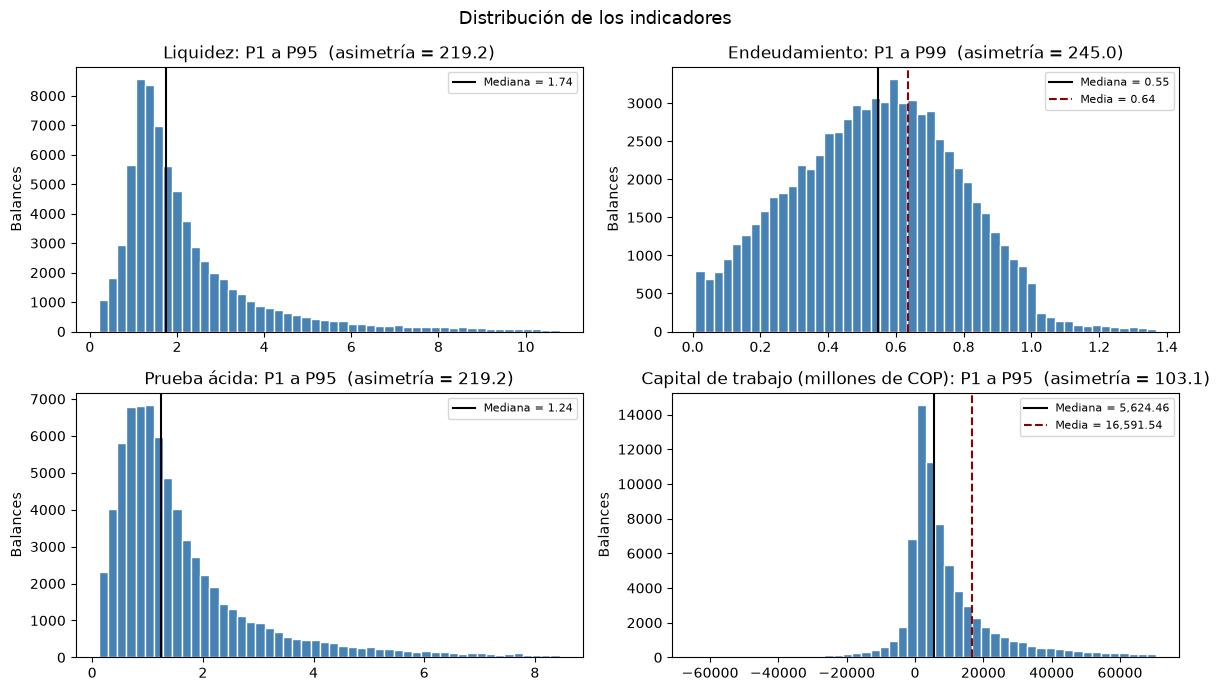

In [6]:
titulos = {"liquidez": "Liquidez", "endeudamiento": "Endeudamiento",
           "prueba_acida": "Prueba ácida", "capital_trabajo": "Capital de trabajo (millones de COP)"}
limite_superior = {"liquidez": 95, "endeudamiento": 99, "prueba_acida": 95, "capital_trabajo": 95}
escala = {"capital_trabajo": 1_000}  # de miles a millones de pesos, solo para graficar

fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
for eje, (c, x) in zip(ejes.ravel(), datos.items()):
    x_graf = x / escala.get(c, 1)
    p_inf, p_sup = percentil(x_graf, 1), percentil(x_graf, limite_superior[c])
    eje.hist(x_graf[(x_graf >= p_inf) & (x_graf <= p_sup)], bins=50,
             color="steelblue", edgecolor="white")
    eje.axvline(mediana(x_graf), color="black", linewidth=1.5,
                label=f"Mediana = {mediana(x_graf):,.2f}")
    if p_inf <= media(x_graf) <= p_sup:
        eje.axvline(media(x_graf), color="darkred", linestyle="--", linewidth=1.5,
                    label=f"Media = {media(x_graf):,.2f}")
    eje.set_title(f"{titulos[c]}: P1 a P{limite_superior[c]}  (asimetría = {asimetria(x):,.1f})")
    eje.set_ylabel("Balances")
    eje.legend(fontsize=8)
fig.suptitle("Distribución de los indicadores", fontsize=13)
plt.tight_layout()
plt.show()

> **Interpretación:** los cuatro indicadores tienen **asimetría positiva** (cola larga hacia la derecha) y una curtosis muy alta. Esta forma la explican en gran parte unos pocos balances extremos, alrededor del 1 % (758 balances por encima del P99):
>
> - **Endeudamiento:** al recortar entre P1 y P99, la asimetría baja de 245 a 0,23 y la curtosis de 62.818 a 0,12. Sin sus extremos es casi simétrico, con forma de campana alrededor de 0,55, como se ve en el histograma. Sus valores extremos son las empresas con patrimonio muy negativo, que son justamente la señal de deterioro del proyecto, así que no se deben descartar.
> - **Liquidez y prueba ácida:** recortadas, la asimetría baja de 219 a 6,6 y 6,8, pero siguen sesgadas. Es su forma natural: no pueden ser negativas y no tienen techo. La media recortada de la liquidez (3,97) también queda mucho más cerca de la mediana (1,74) que la media original (124,17).
> - **Capital de trabajo:** la asimetría baja de 103 a 3,9. La mayoría de los balances están cerca de cero o algo por encima, con una cola larga de empresas grandes.
>
> En consecuencia, cualquier medida basada en promedios, como la correlación de Pearson o las pruebas que comparan medias, va a ser muy sensible a esos pocos balances. Conviene contrastarla con medidas basadas en rangos y escalar o transformar las variables antes de modelar.

#### Transformación logarítmica de los montos

Las cuentas del balance (activos, pasivos, patrimonio, efectivo) y el capital de trabajo están en
miles de pesos, y en el universo conviven empresas medianas con algunas de las más grandes del
país. Esto hace que sus distribuciones sean todavía más sesgadas que las de los indicadores. La
transformación logarítmica comprime la escala: convierte diferencias multiplicativas (una empresa
diez veces más grande que otra) en diferencias aditivas, y así acerca la distribución a una forma
simétrica.

Se usan dos variantes según el signo de cada cuenta:

- **Cuentas que no son negativas** (activos, pasivos, efectivo): $\log_{10}(1 + x)$. Se suma 1
  para que los valores en cero no den error.
- **Cuentas que pueden ser negativas** (patrimonio y capital de trabajo): logaritmo con signo,
  $\text{signo}(x)\cdot\log_{10}(1 + |x|)$, que conserva si el valor es positivo o negativo.

La tabla compara la asimetría y la curtosis antes y después de transformar.

In [7]:
def log_con_signo(x):
    return np.sign(x) * np.log10(1 + np.abs(x))


MONTOS = ["activo_total", "activo_corriente", "pasivo_total", "efectivo",
          "patrimonio_total", "capital_trabajo"]

filas = []
for c in MONTOS:
    x = fact[c].dropna().to_numpy(dtype=float)
    transformado = log_con_signo(x)
    filas.append({
        "cuenta": c,
        "valores negativos": int((x < 0).sum()),
        "media (miles COP)": media(x),
        "mediana (miles COP)": mediana(x),
        "asimetría original": asimetria(x),
        "asimetría log": asimetria(transformado),
        "curtosis original": curtosis(x),
        "curtosis log": curtosis(transformado),
    })
efecto_log = pd.DataFrame(filas).set_index("cuenta")
with pd.option_context("display.float_format", "{:,.2f}".format):
    print(efecto_log)

                  valores negativos  media (miles COP)  mediana (miles COP)  \
cuenta                                                                        
activo_total                      0     126,059,021.84        27,873,417.00   
activo_corriente                  0      53,186,479.55        15,573,685.00   
pasivo_total                      0      61,662,464.84        13,303,724.00   
efectivo                          0       7,467,423.44         1,385,595.00   
patrimonio_total               2220      64,396,557.00        10,990,277.00   
capital_trabajo               10372      16,591,543.15         5,624,462.50   

                  asimetría original  asimetría log  curtosis original  \
cuenta                                                                   
activo_total                   37.91           0.61           2,389.19   
activo_corriente              125.66          -0.43          20,411.70   
pasivo_total                   59.52          -0.52           5,670.17 

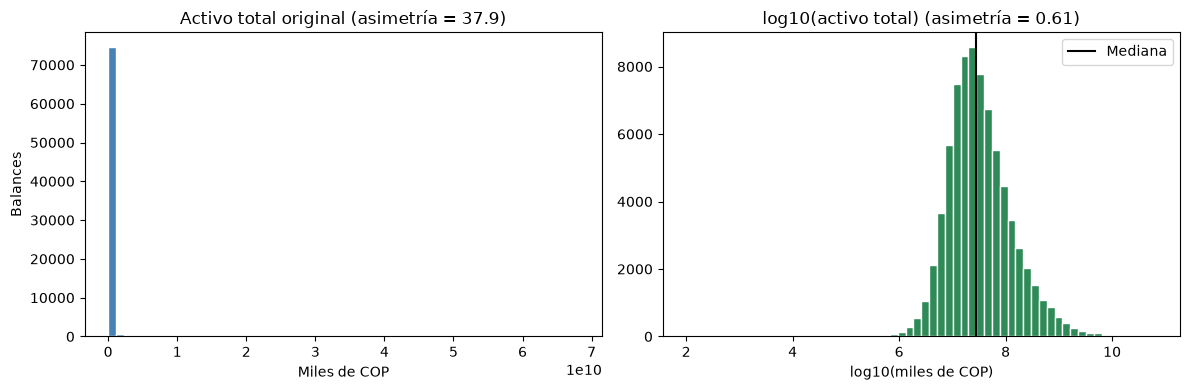

In [8]:
activo = fact["activo_total"].to_numpy(dtype=float)

fig, (izq, der) = plt.subplots(1, 2, figsize=(12, 4))
izq.hist(activo, bins=60, color="steelblue", edgecolor="white")
izq.set_title(f"Activo total original (asimetría = {asimetria(activo):,.1f})")
izq.set_xlabel("Miles de COP")
izq.set_ylabel("Balances")

der.hist(np.log10(activo), bins=60, color="seagreen", edgecolor="white")
der.axvline(np.log10(mediana(activo)), color="black", linewidth=1.5, label="Mediana")
der.set_title(f"log10(activo total) (asimetría = {asimetria(np.log10(activo)):,.2f})")
der.set_xlabel("log10(miles de COP)")
der.legend()
plt.tight_layout()
plt.show()

> **Interpretación:** en las cuentas que nunca son negativas, el logaritmo funciona muy bien. El **activo total** pasa de una asimetría de 37,9 a 0,61 y de una curtosis de 2.389 a 1,21: queda casi simétrico, como se ve en el segundo histograma. Algo parecido pasa con el activo corriente (de 125,7 a −0,43) y el pasivo total (de 59,5 a −0,52). En el **efectivo** queda una cola a la izquierda (asimetría −1,20) por los 195 balances con efectivo en cero. La diferencia entre la media y la mediana muestra por qué hacía falta la transformación: el activo total medio es de 126,1 mil millones de pesos, 4,5 veces la mediana (27,9 mil millones).
>
> En el **patrimonio** y el **capital de trabajo**, el logaritmo con signo reduce la escala (la asimetría pasa de 31,3 a −4,95 y de 103,1 a −2,06), pero no las vuelve simétricas. Los valores positivos y negativos quedan en dos grupos separados. Para esas dos variables es mejor apoyarse en los indicadores relativos (solvencia y liquidez), que ya no dependen del tamaño de la empresa.

#### Resumen

| Hallazgo | Implicación para las siguientes etapas |
|---|---|
| La media está muy por encima de la mediana en todos los indicadores, por unos pocos balances extremos | Describir y comparar con **mediana e IQR**, también en el dashboard |
| Asimetría positiva y curtosis muy altas; al recortar el 1 % extremo, el endeudamiento queda casi simétrico | Contrastar las correlaciones de Pearson con las de Spearman y Kendall, que se basan en rangos |
| Los extremos de endeudamiento son las empresas con patrimonio negativo | Conservarlos: son la señal de deterioro que se quiere anticipar |
| El 13,7 % tiene liquidez menor que 1, el 37,8 % prueba ácida menor que 1 y el 2,9 % patrimonio negativo; combinadas, las señales de deterioro llegan al 14,8 % | La clase de deterioro será minoritaria en el modelo |
| Los montos son muy sesgados y el logaritmo los vuelve casi simétricos, salvo patrimonio y capital de trabajo | Usar log10 si los montos entran a un análisis o modelo; para patrimonio y capital de trabajo, preferir los indicadores relativos |

*Siguiente paso:* tendencias de los indicadores por año, macrosector y región.

### 2.2 Tendencias por año, macrosector y región

La sección anterior describió los indicadores en conjunto. Aquí se mira **cómo cambian**: a lo
largo del tiempo (2019 a 2025, con la pandemia en medio), entre macrosectores y entre regiones.
Son las comparaciones que después alimentan las pruebas de hipótesis y las vistas del dashboard.

| Análisis | Pregunta |
|---|---|
| Evolución de las medianas | ¿Cómo cambiaron la liquidez y el endeudamiento de la empresa típica antes, durante y después del COVID? |
| Boxplots por macrosector | ¿Qué sectores son más líquidos o más endeudados, y cuáles son más heterogéneos? |
| Antioquia vs. resto del país | ¿Las empresas antioqueñas se comportan distinto a las del resto del país? |
| Patrimonio negativo por año | ¿Está creciendo la proporción de empresas en quiebra técnica? |

Decisiones que vienen de la sección 2.1:

- Se resume con la **mediana** y el **IQR**, no con la media, porque unos pocos balances extremos
  arrastran los promedios.
- **Solvencia** no se analiza, porque es `1 − endeudamiento`.
- Los vacíos de liquidez y prueba ácida (98 balances) **no se rellenan**: cada cálculo usa los
  valores disponibles.

Se parte del modelo estrella de la sección 1.4: `fact_indicadores` unida con `dim_empresa`,
`dim_sector` y `dim_tiempo`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PROCESSED = RAIZ / "data" / "processed"

fact = pd.read_csv(DATA_PROCESSED / "fact_indicadores.csv", dtype={"nit": str})
dim_empresa = pd.read_csv(DATA_PROCESSED / "dim_empresa.csv", dtype={"nit": str})
dim_sector = pd.read_csv(DATA_PROCESSED / "dim_sector.csv")
dim_tiempo = pd.read_csv(DATA_PROCESSED / "dim_tiempo.csv")

tendencias = (fact.merge(dim_empresa, on="nit", how="left")
                  .merge(dim_sector, on="id_sector", how="left")
                  .merge(dim_tiempo[["anio", "etapa_covid"]], on="anio", how="left"))
assert len(tendencias) == len(fact), "La unión con las dimensiones duplicó filas"

# Capital de trabajo en millones de pesos (viene en miles) para que las cifras sean legibles
tendencias["capital_trabajo_mill"] = tendencias["capital_trabajo"] / 1_000
# Señal de iliquidez: vacía cuando la liquidez no se pudo calcular
tendencias["liquidez_menor_1"] = (tendencias["liquidez"] < 1).astype(float).where(
    tendencias["liquidez"].notna())
tendencias["antioquia"] = np.where(tendencias["departamento"] == "ANTIOQUIA",
                                   "Antioquia", "Resto del país")

INDICADORES_TEND = ["liquidez", "endeudamiento", "prueba_acida", "capital_trabajo_mill"]
NOMBRES = {"liquidez": "Liquidez", "endeudamiento": "Endeudamiento",
           "prueba_acida": "Prueba ácida", "capital_trabajo_mill": "Capital de trabajo (millones COP)"}

print(f"Balances: {len(tendencias):,} | Empresas: {tendencias['nit'].nunique():,}")
print("Balances sin macrosector:", int(tendencias["macrosector"].isna().sum()),
      "| sin departamento:", int(tendencias["departamento"].isna().sum()))
print("\nBalances por año y etapa del COVID:")
print(tendencias.groupby(["anio", "etapa_covid"]).size().rename("balances").to_string())

Balances: 75,829 | Empresas: 12,761
Balances sin macrosector: 0 | sin departamento: 0

Balances por año y etapa del COVID:
anio  etapa_covid
2019  Antes           9495
2020  Durante         9950
2021  Durante        10435
2022  Después        10990
2023  Después        11647
2024  Después        11490
2025  Después        11822


> **Interpretación:** la unión del modelo estrella conserva los 75.829 balances de 12.761 empresas, sin duplicar filas. Todos los balances tienen macrosector y departamento, así que ninguna comparación de esta sección pierde datos por falta de dimensión. Hay un solo año antes de la pandemia (2019), dos durante (2020-2021) y cuatro después (2022-2025).

#### Evolución de las medianas 2019-2025

Para cada año se calcula la mediana de los indicadores, junto con el porcentaje de balances con
liquidez menor que 1 y con patrimonio negativo.

**Cuidado con la composición.** El número de empresas cambia cada año (de 9.495 en 2019 a 11.822
en 2025), porque entran y salen empresas del universo. Si la mediana cambia, puede ser porque las
empresas cambiaron de verdad o solo porque el grupo es otro. Para separar los dos efectos, la
tendencia se calcula también sobre el **panel balanceado**: solo las empresas que tienen balance
en los siete años. Si las dos curvas se mueven igual, el cambio es real y no se debe a la
composición.

El capital de trabajo está en pesos **nominales**: parte de su crecimiento es inflación, así que
se interpreta con cuidado.

In [2]:
def mediana_iqr(serie):
    q1, q2, q3 = serie.quantile([0.25, 0.5, 0.75])
    return q2, q3 - q1


def resumen_anual(df):
    tabla = df.groupby("anio").agg(
        empresas=("nit", "nunique"),
        **{f"med_{c}": (c, "median") for c in INDICADORES_TEND},
        pct_liquidez_menor_1=("liquidez_menor_1", "mean"),
        pct_patrimonio_negativo=("patrimonio_negativo", "mean"),
    )
    tabla[["pct_liquidez_menor_1", "pct_patrimonio_negativo"]] *= 100
    return tabla


anios_por_empresa = tendencias.groupby("nit")["anio"].nunique()
nits_panel = anios_por_empresa[anios_por_empresa == tendencias["anio"].nunique()].index
panel = tendencias[tendencias["nit"].isin(nits_panel)]

evolucion = resumen_anual(tendencias)
evolucion_panel = resumen_anual(panel)

print(f"Empresas en el panel balanceado (los 7 años): {len(nits_panel):,} "
      f"de {tendencias['nit'].nunique():,}")
with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 140):
    print("\nTodas las empresas:")
    print(evolucion)
    print("\nPanel balanceado:")
    print(evolucion_panel)

Empresas en el panel balanceado (los 7 años): 8,450 de 12,761

Todas las empresas:
      empresas  med_liquidez  med_endeudamiento  med_prueba_acida  med_capital_trabajo_mill  pct_liquidez_menor_1  pct_patrimonio_negativo
anio                                                                                                                                      
2019      9495         1.605              0.562             1.148                 3,795.431                16.113                    2.148
2020      9950         1.733              0.545             1.254                 4,211.560                13.991                    2.513
2021     10435         1.746              0.548             1.228                 5,360.256                12.621                    2.568
2022     10990         1.666              0.577             1.169                 5,884.784                13.448                    2.912
2023     11647         1.772              0.544             1.261                 6

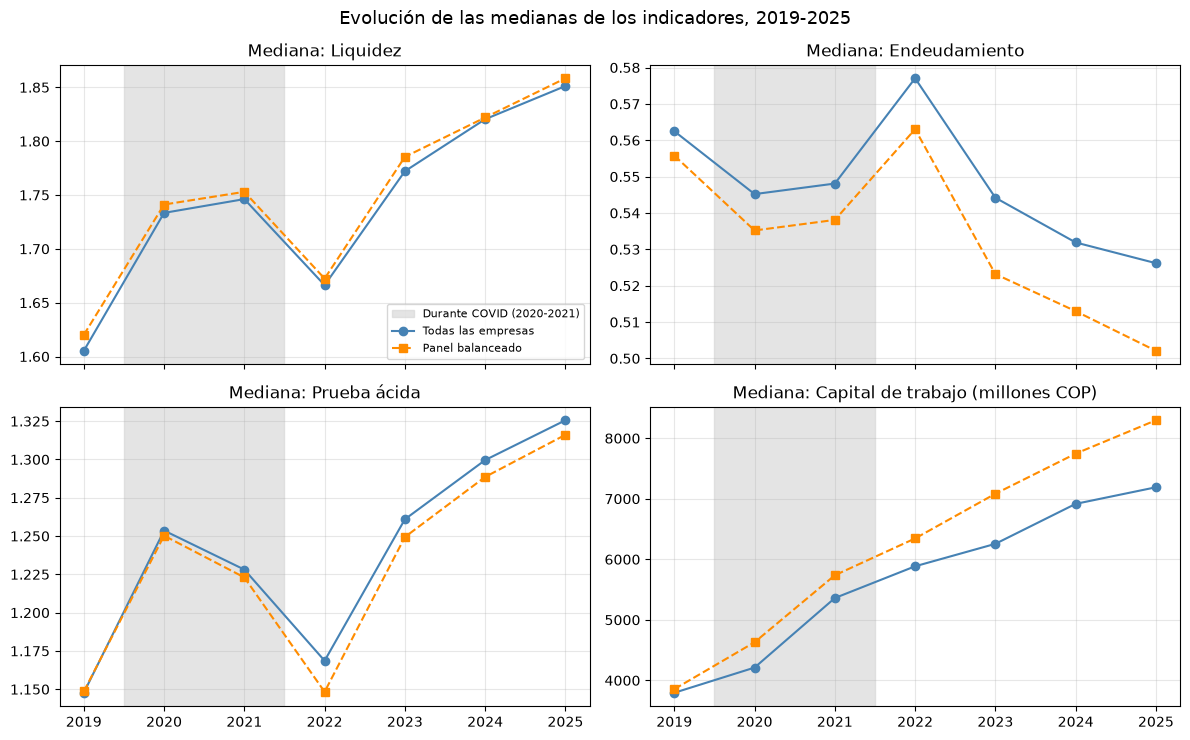

In [3]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
for eje, c in zip(ejes.ravel(), INDICADORES_TEND):
    eje.axvspan(2019.5, 2021.5, color="lightgray", alpha=0.6, label="Durante COVID (2020-2021)")
    eje.plot(evolucion.index, evolucion[f"med_{c}"], marker="o", color="steelblue",
             label="Todas las empresas")
    eje.plot(evolucion_panel.index, evolucion_panel[f"med_{c}"], marker="s", linestyle="--",
             color="darkorange", label="Panel balanceado")
    eje.set_title(f"Mediana: {NOMBRES[c]}")
    eje.grid(alpha=0.3)
ejes[0, 0].legend(fontsize=8)
for eje in ejes[1]:
    eje.set_xticks(evolucion.index)
fig.suptitle("Evolución de las medianas de los indicadores, 2019-2025", fontsize=13)
plt.tight_layout()
plt.show()

> **Interpretación:** contra lo que se podría esperar, la pandemia **no deterioró a la empresa típica del universo**. En 2020 la mediana de liquidez subió de 1,61 a 1,73, la de la prueba ácida de 1,15 a 1,25 y el endeudamiento bajó de 0,562 a 0,545. El porcentaje de balances con liquidez menor que 1 pasó del 16,1 % en 2019 al 12,6 % en 2021. Una posible explicación es que las empresas guardaron caja y frenaron inversiones y pagos ante la incertidumbre. Esa hipótesis se contrasta formalmente en la sección de inferencia.
>
> El año más difícil del periodo fue **2022**: la liquidez cayó a 1,67, la prueba ácida a 1,17 y el endeudamiento llegó a su máximo (0,577). Es el año de mayor inflación y de alzas de tasas de interés en Colombia, un contexto que puede explicar el retroceso. De 2023 a 2025 los indicadores se recuperan y cierran en sus mejores niveles: liquidez de 1,85 y endeudamiento de 0,526.
>
> Las curvas de **todas las empresas** y del **panel balanceado** (8.450 empresas presentes los siete años) se mueven igual, así que estos cambios son reales y no se deben a que entren o salgan empresas. La única diferencia es que el endeudamiento del panel baja más (de 0,556 a 0,502, frente a 0,562 a 0,526): las empresas que permanecen se desendeudan más que las que entran. El capital de trabajo mediano casi se duplica (de 3.795 a 7.190 millones de pesos), pero son pesos nominales y parte de ese crecimiento es inflación.

#### Comparación entre macrosectores

Los boxplots muestran, para cada macrosector, la mediana (línea central), el IQR (la caja) y los
bigotes hasta 1,5 veces el IQR. Los valores atípicos **no se dibujan**: con liquidez de hasta
4 millones aplastarían la escala y no dejarían ver las cajas. La detección formal de atípicos se
hace en la sección siguiente. Los sectores se ordenan de izquierda a derecha de menor a mayor mediana y se usan todos
los balances de 2019 a 2025.

Las líneas punteadas marcan los umbrales de la sección 2.1: liquidez y prueba ácida iguales a 1, y
endeudamiento igual a 1 (patrimonio en cero).

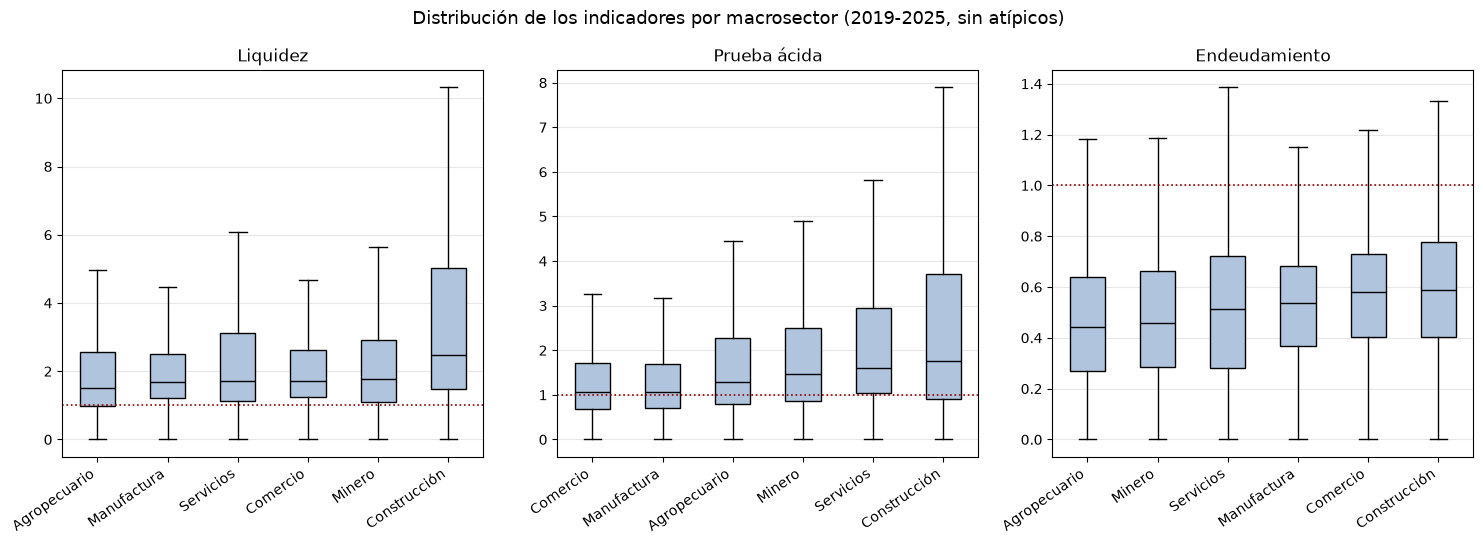

              empresas  balances  med_liquidez  iqr_liquidez  med_prueba_acida  iqr_prueba_acida  med_endeudamiento  iqr_endeudamiento  pct_liquidez_menor_1  \
macrosector                                                                                                                                                    
AGROPECUARIO       616      3808         1.509         1.586             1.284             1.476              0.443              0.368                25.532   
MINERO             266      1646         1.766         1.817             1.465             1.636              0.458              0.377                20.851   
SERVICIOS         3164     18589         1.703         1.986             1.609             1.907              0.514              0.443                19.009   
MANUFACTURA       2562     16120         1.670         1.302             1.064             0.984              0.536              0.314                13.263   
COMERCIO          4805     27575        

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 5.5))
umbral = {"liquidez": 1, "prueba_acida": 1, "endeudamiento": 1}
for eje, c in zip(ejes, ["liquidez", "prueba_acida", "endeudamiento"]):
    orden = tendencias.groupby("macrosector")[c].median().sort_values().index
    grupos = [tendencias.loc[tendencias["macrosector"] == s, c].dropna() for s in orden]
    eje.boxplot(grupos, showfliers=False, patch_artist=True,
                boxprops={"facecolor": "lightsteelblue"}, medianprops={"color": "black"})
    eje.set_xticks(range(1, len(orden) + 1), [s.capitalize() for s in orden], rotation=35, ha="right")
    eje.axhline(umbral[c], color="darkred", linestyle=":", linewidth=1.2)
    eje.set_title(NOMBRES[c])
    eje.grid(axis="y", alpha=0.3)
fig.suptitle("Distribución de los indicadores por macrosector (2019-2025, sin atípicos)", fontsize=13)
plt.tight_layout()
plt.show()

filas = []
for sector, g in tendencias.groupby("macrosector"):
    fila = {"macrosector": sector, "empresas": g["nit"].nunique(), "balances": len(g)}
    for c in ["liquidez", "prueba_acida", "endeudamiento"]:
        fila[f"med_{c}"], fila[f"iqr_{c}"] = mediana_iqr(g[c].dropna())
    fila["pct_liquidez_menor_1"] = g["liquidez_menor_1"].mean() * 100
    fila["pct_patrimonio_negativo"] = g["patrimonio_negativo"].mean() * 100
    filas.append(fila)
por_sector = pd.DataFrame(filas).set_index("macrosector").sort_values("med_endeudamiento")
with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 160):
    print(por_sector)

Además de comparar los sectores en conjunto, conviene ver si la pandemia los afectó por igual.
El gráfico muestra la mediana de liquidez y de endeudamiento de cada macrosector por año.

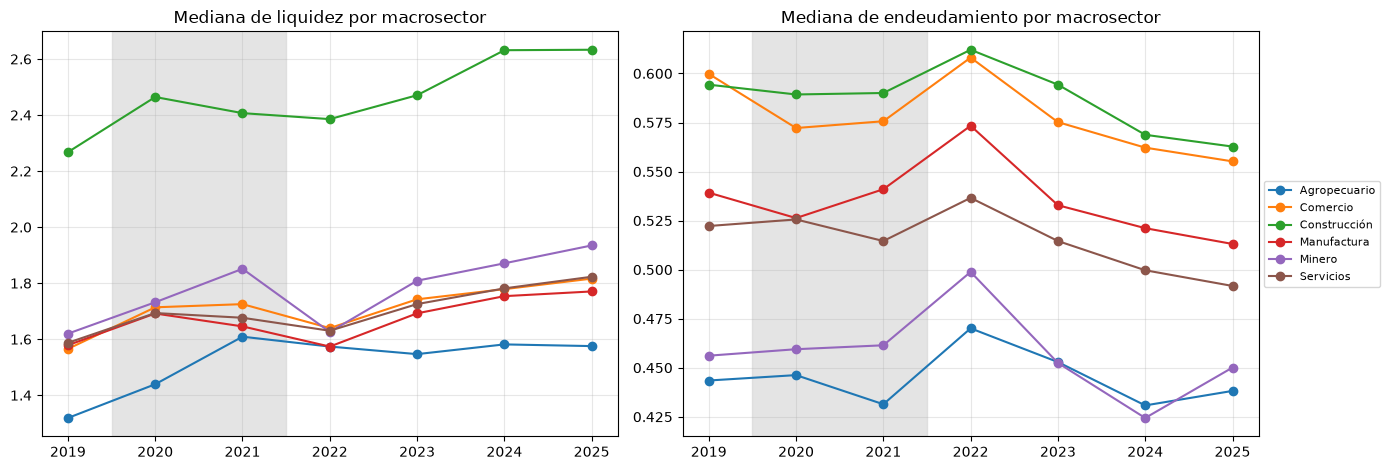

Mediana de endeudamiento por macrosector:
anio          2019  2021  2025  cambio 2019-2025 (puntos)
macrosector                                              
COMERCIO     0.600 0.576 0.555                     -4.460
CONSTRUCCIÓN 0.594 0.590 0.563                     -3.155
SERVICIOS    0.522 0.515 0.492                     -3.055
MANUFACTURA  0.539 0.541 0.513                     -2.615
MINERO       0.456 0.461 0.450                     -0.605
AGROPECUARIO 0.444 0.431 0.438                     -0.530


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True)
for eje, c in zip(ejes, ["liquidez", "endeudamiento"]):
    eje.axvspan(2019.5, 2021.5, color="lightgray", alpha=0.6)
    medianas = tendencias.pivot_table(index="anio", columns="macrosector", values=c, aggfunc="median")
    for sector in medianas.columns:
        eje.plot(medianas.index, medianas[sector], marker="o", label=sector.capitalize())
    eje.set_title(f"Mediana de {NOMBRES[c].lower()} por macrosector")
    eje.set_xticks(medianas.index)
    eje.grid(alpha=0.3)
ejes[1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

cambio = tendencias.pivot_table(index="macrosector", columns="anio", values="endeudamiento",
                                aggfunc="median")[[2019, 2021, 2025]]
cambio["cambio 2019-2025 (puntos)"] = (cambio[2025] - cambio[2019]) * 100
print("Mediana de endeudamiento por macrosector:")
with pd.option_context("display.float_format", "{:,.3f}".format):
    print(cambio.sort_values("cambio 2019-2025 (puntos)"))

> **Interpretación:** los macrosectores tienen perfiles financieros distintos:
>
> - **Construcción** es el sector más líquido (mediana de 2,46) y el más heterogéneo (IQR de 3,54), y a la vez el más endeudado (0,588). Es el que menos balances tiene con liquidez menor que 1 (7,5 %).
> - **Comercio y manufactura** tienen una liquidez parecida a la mediana general (1,71 y 1,67 frente a 1,74), pero su prueba ácida baja a 1,06: dependen del inventario para cubrir sus deudas de corto plazo.
> - **Agropecuario** es el menos líquido (1,51) y el que más balances tiene con liquidez menor que 1 (25,5 %). Sin embargo, es el menos endeudado (0,443) y el que menos patrimonio negativo tiene (1,8 %).
> - **Minero** tiene un endeudamiento mediano bajo (0,458), pero el mayor porcentaje de patrimonio negativo (6,4 %). La mediana esconde un grupo de empresas mineras en quiebra técnica.
> - **Servicios** tiene el endeudamiento más disperso (IQR de 0,443) y el 19 % de sus balances con liquidez menor que 1.
>
> En el tiempo, todos los sectores repiten el patrón general: el endeudamiento sube en 2022 y baja hasta 2025. Comercio es el que más se desendeuda (−4,5 puntos entre 2019 y 2025). Agropecuario mejora su liquidez durante la pandemia (de 1,32 a 1,61) y después se estanca, mientras que construcción la sigue subiendo hasta 2,63. Que el patrimonio negativo varíe tanto entre sectores sugiere que el **macrosector está asociado al deterioro**. Esto se pone a prueba con chi-cuadrado en la sección de inferencia y sirve como variable para el modelo.

#### Antioquia vs. resto del país

Se separan las empresas con domicilio en Antioquia del resto. Se compara el nivel de los
indicadores con todos los balances y su evolución año a año. Aquí la comparación es solo
descriptiva; si se quiere saber si la diferencia es estadísticamente significativa, se usan las
pruebas de la sección de inferencia.

Como contexto, la tabla final resume las regiones definidas en la base de las 10.000 empresas.

antioquia                 Antioquia  Resto del país
empresas                  2,469.000      10,292.000
balances                 14,632.000      61,197.000
med_liquidez                  1.760           1.739
iqr_liquidez                  1.634           1.666
med_prueba_acida              1.217           1.246
iqr_prueba_acida              1.349           1.401
med_endeudamiento             0.548           0.547
iqr_endeudamiento             0.354           0.360
med_capital_trabajo_mill  5,265.060       5,707.978
pct_liquidez_menor_1         13.238          13.802
pct_patrimonio_negativo       2.310           3.075


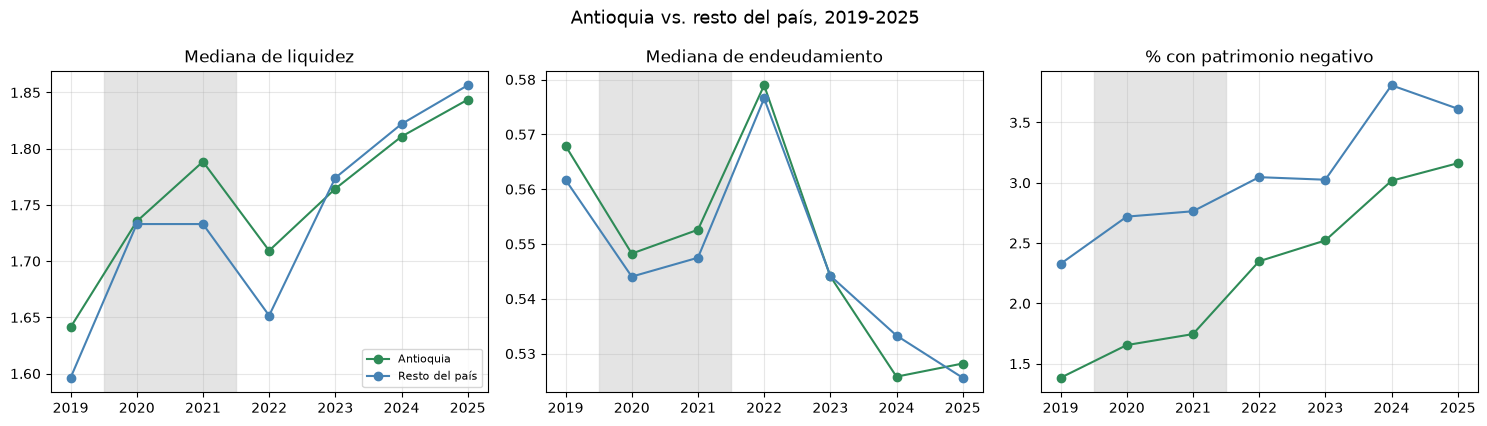

In [6]:
def resumen_grupos(df, columna):
    filas = []
    for grupo, g in df.groupby(columna):
        fila = {columna: grupo, "empresas": g["nit"].nunique(), "balances": len(g)}
        for c in ["liquidez", "prueba_acida", "endeudamiento"]:
            fila[f"med_{c}"], fila[f"iqr_{c}"] = mediana_iqr(g[c].dropna())
        fila["med_capital_trabajo_mill"] = g["capital_trabajo_mill"].median()
        fila["pct_liquidez_menor_1"] = g["liquidez_menor_1"].mean() * 100
        fila["pct_patrimonio_negativo"] = g["patrimonio_negativo"].mean() * 100
        filas.append(fila)
    return pd.DataFrame(filas).set_index(columna)


with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 160):
    print(resumen_grupos(tendencias, "antioquia").T)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True)
for eje, (c, titulo) in zip(ejes, [("liquidez", "Mediana de liquidez"),
                                   ("endeudamiento", "Mediana de endeudamiento"),
                                   ("patrimonio_negativo", "% con patrimonio negativo")]):
    eje.axvspan(2019.5, 2021.5, color="lightgray", alpha=0.6)
    funcion = "mean" if c == "patrimonio_negativo" else "median"
    serie = tendencias.pivot_table(index="anio", columns="antioquia", values=c, aggfunc=funcion)
    if c == "patrimonio_negativo":
        serie = serie * 100
    for grupo, color in [("Antioquia", "seagreen"), ("Resto del país", "steelblue")]:
        eje.plot(serie.index, serie[grupo], marker="o", color=color, label=grupo)
    eje.set_title(titulo)
    eje.set_xticks(serie.index)
    eje.grid(alpha=0.3)
ejes[0].legend(fontsize=8)
fig.suptitle("Antioquia vs. resto del país, 2019-2025", fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
por_region = resumen_grupos(tendencias, "region").sort_values("empresas", ascending=False)
columnas = ["empresas", "balances", "med_liquidez", "med_endeudamiento",
            "pct_liquidez_menor_1", "pct_patrimonio_negativo"]
with pd.option_context("display.float_format", "{:,.3f}".format, "display.width", 160):
    print(por_region[columnas])

                       empresas  balances  med_liquidez  med_endeudamiento  pct_liquidez_menor_1  pct_patrimonio_negativo
region                                                                                                                   
BOGOTÁ - CUNDINAMARCA      6105     36719         1.726              0.548                14.665                    4.009
ANTIOQUIA                  2469     14632         1.760              0.548                13.238                    2.310
COSTA PACÍFICA             1290      7701         1.610              0.566                13.542                    1.467
REGIÓN CARIBE               832      4913         1.720              0.547                12.151                    1.181
CENTRO - ORIENTE            737      4188         1.922              0.516                11.565                    1.146
EJE CAFETERO                475      2716         1.772              0.553                12.422                    3.351
COSTA ATLÁNTICA         

> **Interpretación:** Antioquia reúne 2.469 empresas (19,3 % del universo) y, en la empresa típica, **se comporta casi igual que el resto del país**. Las medianas de liquidez (1,76 frente a 1,74), endeudamiento (0,548 frente a 0,547) y prueba ácida (1,22 frente a 1,25) son prácticamente las mismas, y sus curvas se mueven juntas año a año, incluida la caída de 2022. La diferencia está en la cola: Antioquia tiene **menos empresas con patrimonio negativo** (2,3 % frente a 3,1 %) en todos los años. Esa ventaja se está cerrando: en 2019 el porcentaje era 1,38 % frente a 2,33 %, y en 2025 fue 3,16 % frente a 3,61 %. En Antioquia el patrimonio negativo se multiplicó por 2,3 y en el resto del país por 1,5.
>
> Por regiones, Bogotá-Cundinamarca concentra casi la mitad de las empresas (6.105) y tiene el mayor porcentaje de patrimonio negativo (4,0 %), seguida de Costa Atlántica (3,5 %) y Eje Cafetero (3,4 %). Las regiones con menos empresas (Llanos, Centro-Sur y Otros) muestran mejores indicadores, pero con tan pocas empresas sus porcentajes son menos estables.
>
> **Nota para el dashboard:** en `dim_empresa` hay departamentos escritos de dos formas: *VALLE* y *VALLE DEL CAUCA*, y *NARINO* y *NARIÑO*. No afecta esta sección, que usa Antioquia y la región, pero hay que unificarlos antes de segmentar por departamento.

#### Empresas con patrimonio negativo por año

Una empresa con **patrimonio negativo** debe más de lo que tiene: está en quiebra técnica. Es una
de las dos señales que definen el deterioro en este proyecto, así que interesa ver si su
frecuencia cambia en el tiempo. Se calcula el porcentaje para todas las empresas y para el panel
balanceado, y se desagrega por macrosector.

 anio etapa_covid  balances  patrimonio_negativo  % todas  % panel balanceado
 2019       Antes      9495                  204     2.15                1.83
 2020     Durante      9950                  250     2.51                2.12
 2021     Durante     10435                  268     2.57                1.96
 2022     Después     10990                  320     2.91                2.01
 2023     Después     11647                  341     2.93                2.02
 2024     Después     11490                  420     3.66                2.71
 2025     Después     11822                  417     3.53                2.89


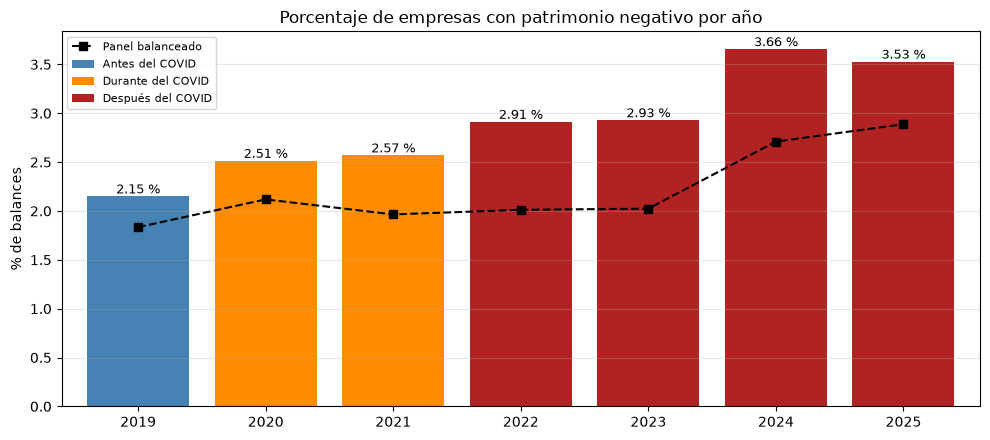


% con patrimonio negativo por macrosector y año:
anio          2019  2020  2021  2022  2023  2024  2025
macrosector                                           
AGROPECUARIO  2.19  1.75  1.31  1.67  1.59  1.78  2.55
COMERCIO      2.28  2.36  2.31  2.56  2.64  3.36  3.11
CONSTRUCCIÓN  1.98  1.64  2.53  2.98  3.29  4.26  4.44
MANUFACTURA   1.23  1.52  1.82  2.34  2.28  2.93  2.71
MINERO        4.76  6.42  6.90  6.15  6.35  6.88  7.00
SERVICIOS     2.63  3.86  3.49  3.83  3.69  4.53  4.40


In [8]:
negativo = tendencias.groupby(["anio", "etapa_covid"]).agg(
    balances=("nit", "size"),
    patrimonio_negativo=("patrimonio_negativo", "sum"),
).reset_index()
negativo["% todas"] = negativo["patrimonio_negativo"] / negativo["balances"] * 100
negativo["% panel balanceado"] = (panel.groupby("anio")["patrimonio_negativo"].mean() * 100).values
print(negativo.to_string(index=False, float_format="{:,.2f}".format))

fig, eje = plt.subplots(figsize=(10, 4.5))
colores = {"Antes": "steelblue", "Durante": "darkorange", "Después": "firebrick"}
barras = eje.bar(negativo["anio"], negativo["% todas"],
                 color=negativo["etapa_covid"].map(colores))
eje.bar_label(barras, labels=[f"{v:.2f} %" for v in negativo["% todas"]], fontsize=9)
eje.plot(negativo["anio"], negativo["% panel balanceado"], marker="s", linestyle="--",
         color="black", label="Panel balanceado")
for etapa, color in colores.items():
    eje.bar(0, 0, color=color, label=f"{etapa} del COVID")
eje.set_xlim(2018.4, 2025.6)
eje.set_xticks(negativo["anio"])
eje.set_ylabel("% de balances")
eje.set_title("Porcentaje de empresas con patrimonio negativo por año")
eje.legend(fontsize=8, loc="upper left")
eje.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\n% con patrimonio negativo por macrosector y año:")
print((tendencias.pivot_table(index="macrosector", columns="anio",
                              values="patrimonio_negativo", aggfunc="mean") * 100).round(2))

> **Interpretación:** la proporción de empresas con patrimonio negativo **crece de forma sostenida**: del 2,15 % en 2019 (204 empresas) al 3,53 % en 2025 (417). El número de empresas en quiebra técnica se duplicó, mientras que el universo creció solo un 25 %. Durante la pandemia el aumento fue moderado (2,51 % y 2,57 %); el mayor salto llegó en **2024**, cuando alcanzó su máximo (3,66 %).
>
> El panel balanceado ayuda a separar dos efectos. En las empresas que están todos los años, el porcentaje se mantuvo cerca del 2 % entre 2020 y 2023, así que parte del aumento de esos años se debe a que entraron empresas más frágiles. En cambio, el salto de 2024 (de 2,02 % a 2,71 %) aparece también en el panel: **es un deterioro reciente y real**. Por sector, construcción pasó de 1,98 % a 4,44 % y manufactura de 1,23 % a 2,71 %; minero se mantiene como el sector más afectado (7,0 % en 2025).
>
> Este resultado complementa la evolución de las medianas. La empresa típica mejora, pero **la cola de empresas más débiles crece**. Por eso el deterioro que el modelo debe anticipar no se ve en la mediana, sino en una minoría que aumenta con el tiempo.

#### Resumen

| Hallazgo | Implicación para las siguientes etapas |
|---|---|
| En 2020 la liquidez mediana subió y el endeudamiento bajó; el peor año fue 2022 y desde 2023 los indicadores se recuperan | Contrastar 2019 vs. 2020 y 2019 vs. 2023 con pruebas de hipótesis; en el dashboard, mostrar la evolución por etapa del COVID |
| Las tendencias del panel balanceado coinciden con las de todas las empresas | Los cambios son reales y no un efecto de qué empresas entran o salen |
| Los macrosectores tienen perfiles distintos: construcción es la más líquida y endeudada, agropecuario la menos líquida y minero la de más patrimonio negativo | Probar la asociación macrosector-patrimonio negativo con chi-cuadrado; usar el macrosector como variable codificada en el modelo |
| Antioquia y el resto del país tienen medianas casi iguales; Antioquia tiene menos patrimonio negativo, pero la brecha se cierra | La región aporta poco a la empresa típica; su efecto está en la cola |
| El patrimonio negativo pasó del 2,15 % al 3,53 %, con un salto real en 2024 | La clase de deterioro crece en los años recientes: la división temporal del modelo debe tenerlo en cuenta al comparar entrenamiento y prueba |
| Hay departamentos con dos nombres (Valle, Nariño) | Unificarlos antes de usar el departamento en el dashboard |

*Siguiente paso:* correlaciones entre indicadores y detección de anomalías.